In [ ]:
# df_merged_combined.to_csv("df_merged_combined_transformed.csv", index=False)

### Data Ingestion



In [ ]:
#  Load
import pandas as pd
import numpy as np

DATA_DIR = r"C:\Users\ethan\Favorites\PISAxECAIR-Research\data\transformed"

df_merged_2018 = pd.read_csv(rf"{DATA_DIR}\df_merged_2018_transformed.csv")
df_merged_2022 = pd.read_csv(rf"{DATA_DIR}\df_merged_2022_transformed.csv")
df_merged_combined = pd.read_csv(rf"{DATA_DIR}\df_merged_combined_transformed_noinf.csv")
# df_merged_combined = pd.read_csv(r"C:\Users\ethan\Downloads\df_merged_combined_transformed_noinf_with_mean_ESCS.csv")

# df_stu_2018 = pd.read_sas(r"C:\Users\ethan\Downloads\SAS_STU_QQQ\STU\cy07_msu_stu_qqq.sas7bdat", format="sas7bdat")
# df_stu_2022 = pd.read_sas(r"C:\Users\ethan\Downloads\SCH_QQQ_SAS (1)\CY08MSP_SCH_QQQ.SAS7BDAT", format="sas7bdat")

In [2]:
df_merged_combined 

,CNT_x,CNTSCHID,STRATUM,SC013Q01TA,SC037Q02TA,SC061Q01TA,SC025Q01NA,YEAR,EXT_FUND,EDU_MAT,...,STU_TCH,STU_COMP,TCH_COMP,X_ACTIV,PRNT_ENG,CNT_y,MATH_school_weighted,READ_school_weighted,SCIE_school_weighted,ALL_DOMAINS_school_weighted
0,BRN,9600001.0,BRN0308,2.0,3.0,1.0,18.0,2018,100.0,1.0,...,19.1751,2.7619,11.0625,4.0,13.75,BRN,496.179785,488.884382,504.064875,496.376347
1,BRN,9600002.0,BRN0102,1.0,1.0,2.0,91.0,2018,5.0,2.0,...,8.5676,2.0167,4.9333,5.0,42.50,BRN,372.827246,340.491833,368.287536,360.535539
2,BRN,9600003.0,BRN0102,1.0,1.0,1.0,100.0,2018,10.0,3.0,...,9.1188,2.4375,1.2625,3.0,27.75,BRN,429.738457,420.526131,443.029055,431.097881
3,BRN,9600004.0,BRN0202,1.0,1.0,2.0,100.0,2018,73.0,2.0,...,9.2586,2.1200,3.8667,5.0,25.50,BRN,379.067386,347.880933,372.468728,366.472349
4,BRN,9600005.0,BRN0308,2.0,1.0,2.0,95.0,2018,100.0,2.0,...,15.6078,4.5429,1.0000,6.0,39.00,BRN,457.045148,455.718475,466.915760,459.893128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3087,THA,76400276.0,THA97,1.0,1.0,2.0,100.0,2022,0.0,2.0,...,19.6486,0.7000,3.7000,6.0,41.00,THA,377.752653,358.240835,411.188796,382.394095
3088,THA,76400277.0,THA97,1.0,1.0,3.0,85.0,2022,85.0,3.0,...,23.6757,1.6200,0.7400,4.0,69.00,THA,494.806138,474.063689,509.352244,492.740690
3089,THA,76400278.0,THA97,1.0,1.0,2.0,90.0,2022,30.0,1.0,...,20.0057,12.0000,1.7500,5.0,73.50,THA,462.219310,461.652469,487.667973,470.513251
3090,THA,76400279.0,THA97,1.0,1.0,1.0,100.0,2022,2.0,1.0,...,13.6111,0.8929,1.2857,4.0,56.00,THA,513.559200,432.402900,521.115300,489.025800


In [61]:
# key checks
def check_key_uniqueness(df, key_cols=("CNT_x", "CNT", "CNTSCHID", "YEAR"), expected_n={2018: 1286, 2022: 1655}):
    # 2a. Rows by cycle
    print("Shape:", df.shape, f"| expected ~{sum(expected_n.values()):,} rows {expected_n}\n")
    print("Row counts by YEAR:\n", df["YEAR"].value_counts(dropna=False), "\n", sep="")

    # 2b. CNTSCHID alone (cross-cycle collisions are expected)
    counts = df["CNTSCHID"].value_counts()
    print(f"Rows whose CNTSCHID is duplicated:     {df['CNTSCHID'].duplicated(keep=False).mean() * 100:.2f}%")
    print(f"CNTSCHID values that are duplicated:   {counts.gt(1).sum() / counts.size * 100:.2f}%\n")

    # 2c. The real check: composite key
    key = [c for c in key_cols if c in df.columns]
    n_dup = df.duplicated(subset=key, keep=False).sum()
    print(f"Rows duplicated on {'+'.join(key)}: {n_dup} ({n_dup / len(df) * 100:.2f}%)")
    if n_dup == 0:
        print(" Composite key is unique — CNTSCHID overlap is only cross-cycle ID collision.")
        return
    print(" Composite key is NOT unique. First offending groups:")
    display(df[df.duplicated(subset=key, keep=False)].sort_values(key)[key].head(20))
    # 2d. Identical copies vs genuinely different records
    print(f"Fully identical rows among them: {df.duplicated(keep=False).sum()} "
          "(if smaller than the count above, records differ → real fan-out problem)")


check_key_uniqueness(df_merged_combined)

Shape: (3092, 22) | expected ~2,941 rows {2018: 1286, 2022: 1655}

Row counts by YEAR:
YEAR
2022    1655
2018    1437
Name: count, dtype: int64

Rows whose CNTSCHID is duplicated:     91.79%
CNTSCHID values that are duplicated:   84.82%

Rows duplicated on CNT_x+CNTSCHID+YEAR: 0 (0.00%)
 Composite key is unique — CNTSCHID overlap is only cross-cycle ID collision.


In [62]:
# row checks
def check_target_completeness(df, target_cols, expected_n={2018: 1286, 2022: 1655}):
    target_cols = [c for c in target_cols if c in df.columns]
    print("Missing target values by YEAR:")
    display(df.groupby("YEAR")[target_cols].apply(lambda g: g.isna().sum()))

    complete = df.dropna(subset=target_cols)
    actual = complete["YEAR"].value_counts().to_dict()
    print(f"Table 4: {expected_n} | total = {sum(expected_n.values()):,}")
    print(f"Actual:  { {y: actual.get(y, 0) for y in expected_n} } | total = {len(complete):,}")

    if len(complete) == sum(expected_n.values()):
        print(" Dropping rows with missing targets reconciles with Table 4.")
    else:
        print("⚠️ Still does not match Table 4 — inspect the remaining gap.")
    return complete


df_target_complete = check_target_completeness(
    df_merged_combined, ["READ_school_weighted", "SCIE_school_weighted", "MATH_school_weighted"]
)

Missing target values by YEAR:


,READ_school_weighted,SCIE_school_weighted,MATH_school_weighted
YEAR,,,
2018,151,151,151
2022,0,0,0


Table 4: {2018: 1286, 2022: 1655} | total = 2,941
Actual:  {2018: 1286, 2022: 1655} | total = 2,941
 Dropping rows with missing targets reconciles with Table 4.


In [ ]:
# data missingness check
df_merged_combined.isna().agg(["sum", "mean"]).T.rename(columns={"sum": "n_missing", "mean": "pct_missing"})

,n_missing,pct_missing
CNT_x,0.0,0.000000
CNTSCHID,0.0,0.000000
STRATUM,0.0,0.000000
SC013Q01TA,0.0,0.000000
SC037Q02TA,0.0,0.000000
SC061Q01TA,0.0,0.000000
SC025Q01NA,0.0,0.000000
YEAR,0.0,0.000000
EXT_FUND,0.0,0.000000
EDU_MAT,0.0,0.000000


In [6]:
df_merged_combined["SC013Q01TA"].value_counts(dropna=False)

SC013Q01TA
1.0    2531
2.0     561
Name: count, dtype: int64

In [7]:
df_merged_combined.groupby("SC013Q01TA")["READ_school_weighted"].mean()

SC013Q01TA
1.0    400.233059
2.0    392.990598
Name: READ_school_weighted, dtype: float64

In [63]:
# used_features = ols_read_pooled["used_features"]
# used_features

In [9]:
df_merged_combined.groupby(["CNT_x", "SC013Q01TA"])["READ_school_weighted"].mean().unstack()

SC013Q01TA,1.0,2.0
CNT_x,,
BRN,410.207505,479.586434
IDN,380.032295,363.617346
KHM,314.496873,365.467459
MYS,399.955581,416.692042
PHL,330.795323,401.467106
SGP,537.749156,568.130824
THA,393.519734,380.065858
VNM,446.784490,474.383405


In [10]:
df_merged_combined.groupby(["CNT_x","SC013Q01TA"]).size().unstack(fill_value=0)

SC013Q01TA,1.0,2.0
CNT_x,,
BRN,81,28
IDN,503,304
KHM,172,11
MYS,363,27
PHL,306,69
SGP,299,31
THA,499,70
VNM,308,21


In [11]:
df_merged_combined["SC013Q01TA"].unique()

array([2., 1.])

In [12]:
df_merged_2018

,CNT_x,CNTSCHID,STRATUM,SC013Q01TA,SC037Q02TA,SC061Q01TA,SC025Q01NA,YEAR,EXT_FUND,EDU_MAT,...,STU_TCH,STU_COMP,TCH_COMP,X_ACTIV,PRNT_ENG,CNT_y,MATH_school_weighted,READ_school_weighted,SCIE_school_weighted,ALL_DOMAINS_school_weighted
0,BRN,9600001.0,BRN0308,2.0,3.0,1.0,18.0,2018,100.0,1.0,...,19.1751,2.7619,11.0625,4.0,13.75,BRN,496.179785,488.884382,504.064875,496.376347
1,BRN,9600002.0,BRN0102,1.0,1.0,2.0,91.0,2018,5.0,2.0,...,8.5676,2.0167,4.9333,5.0,42.50,BRN,372.827246,340.491833,368.287536,360.535539
2,BRN,9600003.0,BRN0102,1.0,1.0,1.0,100.0,2018,10.0,3.0,...,9.1188,2.4375,1.2625,3.0,27.75,BRN,429.738457,420.526131,443.029055,431.097881
3,BRN,9600004.0,BRN0202,1.0,1.0,2.0,100.0,2018,73.0,2.0,...,9.2586,2.1200,3.8667,5.0,25.50,BRN,379.067386,347.880933,372.468728,366.472349
4,BRN,9600005.0,BRN0308,2.0,1.0,2.0,95.0,2018,100.0,2.0,...,15.6078,4.5429,1.0000,6.0,39.00,BRN,457.045148,455.718475,466.915760,459.893128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1432,THA,76400287.0,THA9797,1.0,1.0,2.0,100.0,2018,80.0,2.0,...,12.5401,1.3500,2.2833,6.0,75.00,THA,464.232301,451.242187,492.278929,469.251139
1433,THA,76400288.0,THA9797,1.0,1.0,1.0,99.0,2018,0.0,1.0,...,9.4605,1.0000,1.2667,6.0,61.75,THA,568.861766,507.302117,554.647054,543.603646
1434,THA,76400289.0,THA9797,1.0,1.0,2.0,98.0,2018,27.0,2.0,...,19.2283,3.0750,2.5400,6.0,32.50,THA,416.958464,391.888077,429.285592,412.710711
1435,THA,76400290.0,THA9797,1.0,1.0,1.0,100.0,2018,0.0,2.0,...,0.2500,1.2000,1.2000,6.0,57.50,THA,414.379600,363.084400,419.156067,398.873356


In [13]:
df_merged_combined

,CNT_x,CNTSCHID,STRATUM,SC013Q01TA,SC037Q02TA,SC061Q01TA,SC025Q01NA,YEAR,EXT_FUND,EDU_MAT,...,STU_TCH,STU_COMP,TCH_COMP,X_ACTIV,PRNT_ENG,CNT_y,MATH_school_weighted,READ_school_weighted,SCIE_school_weighted,ALL_DOMAINS_school_weighted
0,BRN,9600001.0,BRN0308,2.0,3.0,1.0,18.0,2018,100.0,1.0,...,19.1751,2.7619,11.0625,4.0,13.75,BRN,496.179785,488.884382,504.064875,496.376347
1,BRN,9600002.0,BRN0102,1.0,1.0,2.0,91.0,2018,5.0,2.0,...,8.5676,2.0167,4.9333,5.0,42.50,BRN,372.827246,340.491833,368.287536,360.535539
2,BRN,9600003.0,BRN0102,1.0,1.0,1.0,100.0,2018,10.0,3.0,...,9.1188,2.4375,1.2625,3.0,27.75,BRN,429.738457,420.526131,443.029055,431.097881
3,BRN,9600004.0,BRN0202,1.0,1.0,2.0,100.0,2018,73.0,2.0,...,9.2586,2.1200,3.8667,5.0,25.50,BRN,379.067386,347.880933,372.468728,366.472349
4,BRN,9600005.0,BRN0308,2.0,1.0,2.0,95.0,2018,100.0,2.0,...,15.6078,4.5429,1.0000,6.0,39.00,BRN,457.045148,455.718475,466.915760,459.893128
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3087,THA,76400276.0,THA97,1.0,1.0,2.0,100.0,2022,0.0,2.0,...,19.6486,0.7000,3.7000,6.0,41.00,THA,377.752653,358.240835,411.188796,382.394095
3088,THA,76400277.0,THA97,1.0,1.0,3.0,85.0,2022,85.0,3.0,...,23.6757,1.6200,0.7400,4.0,69.00,THA,494.806138,474.063689,509.352244,492.740690
3089,THA,76400278.0,THA97,1.0,1.0,2.0,90.0,2022,30.0,1.0,...,20.0057,12.0000,1.7500,5.0,73.50,THA,462.219310,461.652469,487.667973,470.513251
3090,THA,76400279.0,THA97,1.0,1.0,1.0,100.0,2022,2.0,1.0,...,13.6111,0.8929,1.2857,4.0,56.00,THA,513.559200,432.402900,521.115300,489.025800


### Modifying PV To Disaggregated

In [15]:
df_merged_2018.head()

,CNT_x,CNTSCHID,STRATUM,SC013Q01TA,SC037Q02TA,SC061Q01TA,SC025Q01NA,YEAR,EXT_FUND,EDU_MAT,...,STU_TCH,STU_COMP,TCH_COMP,X_ACTIV,PRNT_ENG,CNT_y,MATH_school_weighted,READ_school_weighted,SCIE_school_weighted,ALL_DOMAINS_school_weighted
0,BRN,9600001.0,BRN0308,2.0,3.0,1.0,18.0,2018,100.0,1.0,...,19.1751,2.7619,11.0625,4.0,13.75,BRN,496.179785,488.884382,504.064875,496.376347
1,BRN,9600002.0,BRN0102,1.0,1.0,2.0,91.0,2018,5.0,2.0,...,8.5676,2.0167,4.9333,5.0,42.50,BRN,372.827246,340.491833,368.287536,360.535539
2,BRN,9600003.0,BRN0102,1.0,1.0,1.0,100.0,2018,10.0,3.0,...,9.1188,2.4375,1.2625,3.0,27.75,BRN,429.738457,420.526131,443.029055,431.097881
3,BRN,9600004.0,BRN0202,1.0,1.0,2.0,100.0,2018,73.0,2.0,...,9.2586,2.1200,3.8667,5.0,25.50,BRN,379.067386,347.880933,372.468728,366.472349
4,BRN,9600005.0,BRN0308,2.0,1.0,2.0,95.0,2018,100.0,2.0,...,15.6078,4.5429,1.0000,6.0,39.00,BRN,457.045148,455.718475,466.915760,459.893128


### [Results Used] Full Iterated XGBoost for Combined Years XGBoost, SHAP, Counterfactuals

The final 20% test set is stratified by country × PISA cycle, Optuna tuning is conducted only within the 80% training set.  Median imputation only as guardrails. After tuning, the final imputer and XGBoost model are fitted only on the training data and evaluated once on the untouched test set.
The section also adds robustness checks for predictor stability across PISA cycles. SHAP explanations and the downstream counterfactual/recourse analysis continue to reuse the same fitted combined-years XGBoost model; the counterfactual cells do not redefine or retrain the main model.



In [ ]:

# pip install optuna xgboost shap dice-ml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import xgboost as xgb
import shap
import optuna

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

SCORE_KEYWORDS = ["MATH", "READ", "SCIE", "PV", "ALL_DOMAIN", "WEIGHTED"]   # outcome-leakage screen
DEFAULT_META_COLS = ["CNT", "CNT_x", "CNT_y", "CNTSCHID", "CNTRYID", "ADMINMODE", "YEAR"]

C:\Users\ethan\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
#  feature matrix 
def _pick_country_col(meta):
    # First available country identifier in the merged PISA data.
    return next((c for c in ["CNT_x", "CNT", "CNT_y"] if c in meta.columns), None)


def prepare_feature_matrix(df, target_col, id_cols, meta_cols):
    # Returns (X, y, meta), leakage-screened, rows with missing target removed.
    available_meta_cols = [c for c in meta_cols if c in df.columns]
    y = df[target_col].copy()
    meta = df[available_meta_cols].copy() if available_meta_cols else pd.DataFrame(index=df.index)

    X = df.drop(columns=id_cols + [target_col], errors="ignore").select_dtypes(include=[np.number]).copy()
    X = X.drop(columns=[c for c in X.columns if any(k in c.upper() for k in SCORE_KEYWORDS)])

    mask = y.notna()                                     # predictor NaNs are imputed later
    X, y, meta = X.loc[mask].copy(), y.loc[mask].copy(), meta.loc[mask].copy()

    X = X.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    all_nan_cols = [c for c in X.columns if X[c].isna().all()]
    if all_nan_cols:
        print(f"Dropping {len(all_nan_cols)} all-NaN columns after coercion.")
        X = X.drop(columns=all_nan_cols)
    return X, y, meta


#  country × year split 
def _country_year_strata(meta, year_col="YEAR"):
    country_col = _pick_country_col(meta)
    if country_col is None:
        raise ValueError("No country column found in metadata (expected CNT_x, CNT, or CNT_y).")
    if year_col not in meta.columns:
        raise ValueError(f"{year_col} is required in metadata for country × year stratification.")
    return (meta[country_col].astype("string").fillna("MISSING_COUNTRY")
            + "__" + meta[year_col].astype("string").fillna("MISSING_YEAR"))


def split_country_year(X, y, meta, test_size=0.20, random_state=42):
    strata = _country_year_strata(meta)
    counts = strata.value_counts()
    if (counts < 2).any():
        raise ValueError(f"Country × year strata with fewer than 2 observations:\n{counts[counts < 2]}")

    train_idx, test_idx = train_test_split(X.index, test_size=test_size,
                                           random_state=random_state, stratify=strata.loc[X.index])

    split_audit = (pd.DataFrame({"stratum": strata,
                                 "split": np.where(strata.index.isin(test_idx), "test", "train")})
                   .groupby(["stratum", "split"]).size().unstack(fill_value=0))
    split_audit["total"] = split_audit.sum(axis=1)
    for part in ("train", "test"):
        if part in split_audit.columns:
            split_audit[f"{part}_pct"] = 100 * split_audit[part] / split_audit["total"]

    print(f"Training observations: {len(train_idx):,} | Untouched test observations: {len(test_idx):,}")
    print("\nCountry × year split audit:")
    display(split_audit)

    return {"X_train_raw": X.loc[train_idx].copy(), "X_test_raw": X.loc[test_idx].copy(),
            "y_train": y.loc[train_idx].copy(), "y_test": y.loc[test_idx].copy(),
            "meta_train": meta.loc[train_idx].copy(), "meta_test": meta.loc[test_idx].copy(),
            "split_audit": split_audit}

In [ ]:
#  Optuna tuning on TRAIN only 
FIXED_XGB_PARAMS = {"objective": "reg:squarederror", "eval_metric": "rmse", "n_jobs": 2, "tree_method": "hist"}


def suggest_xgb_params(trial):
    return {
        "n_estimators":     trial.suggest_int("n_estimators", 300, 1200),
        "learning_rate":    trial.suggest_float("learning_rate", 0.005, 0.05, log=True),
        "max_depth":        trial.suggest_int("max_depth", 3, 10),
        "min_child_weight": trial.suggest_float("min_child_weight", 1, 20),
        "subsample":        trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "reg_lambda":       trial.suggest_float("reg_lambda", 1e-2, 20.0, log=True),
        "reg_alpha":        trial.suggest_float("reg_alpha", 1e-4, 10.0, log=True),
    }


def make_country_year_folds(X_train_raw, meta_train, cv=3, random_state=42):
    train_strata = _country_year_strata(meta_train)
    effective_cv = min(cv, int(train_strata.value_counts().min()))
    if effective_cv < 2:
        raise ValueError("Not enough observations per country × year stratum for stratified CV.")
    if effective_cv != cv:
        print(f"Requested cv={cv}; using cv={effective_cv} because of smallest stratum size.")
    skf = StratifiedKFold(n_splits=effective_cv, shuffle=True, random_state=random_state)
    return list(skf.split(X_train_raw, train_strata))


def tune_xgb_optuna(X_train_raw, y_train, cv_splits, n_trials=100, timeout=None, random_state=42):
    fixed = {**FIXED_XGB_PARAMS, "random_state": random_state}

    def objective(trial):
        # Imputer lives inside the Pipeline → refit within every CV fold (no preprocessing leakage).
        cv_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),
                                ("model", xgb.XGBRegressor(**fixed, **suggest_xgb_params(trial)))])
        scores = cross_val_score(cv_pipeline, X_train_raw, y_train,
                                 scoring="neg_root_mean_squared_error", cv=cv_splits, n_jobs=1)
        return -scores.mean()

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=random_state))
    study.optimize(objective, n_trials=n_trials, timeout=timeout)
    best_params = {**study.best_params, **fixed}
    print("\nBest params:", best_params)
    return best_params, study


#  fit on TRAIN, evaluate once on TEST 
def fit_final_model(X_train_raw, y_train, X_test_raw, y_test, best_params):
    imputer = SimpleImputer(strategy="median")
    X_train = pd.DataFrame(imputer.fit_transform(X_train_raw), columns=X_train_raw.columns, index=X_train_raw.index)
    X_test = pd.DataFrame(imputer.transform(X_test_raw), columns=X_test_raw.columns, index=X_test_raw.index)

    model = xgb.XGBRegressor(**best_params)
    model.fit(X_train, y_train)

    pred = model.predict(X_test)
    metrics = {"mae": mean_absolute_error(y_test, pred),
               "rmse": np.sqrt(mean_squared_error(y_test, pred)),
               "r2": r2_score(y_test, pred)}
    return model, imputer, X_train, X_test, metrics

In [ ]:
#  SHAP on held-out schools 
def compute_xgb_shap(model, X_test, max_n=1000, random_state=42, make_plots=True):
    X_shap = shap.sample(X_test, min(max_n, len(X_test)), random_state=random_state)
    shap_contribs = model.get_booster().predict(
        xgb.DMatrix(X_shap, feature_names=list(X_shap.columns)), pred_contribs=True)
    shap_values, shap_base_values = shap_contribs[:, :-1], shap_contribs[:, -1]   # last col = bias

    shap_df = pd.DataFrame(shap_values, columns=X_shap.columns, index=X_shap.index)
    shap_importance = shap_df.abs().mean().sort_values(ascending=False).rename("mean_abs_shap")

    if make_plots:
        for kind in ("bar", None):
            print(f"\nSHAP Summary ({'mean absolute contribution' if kind else 'beeswarm'}):")
            shap.summary_plot(shap_values, X_shap, plot_type=kind, show=False, max_display=30)
            plt.tight_layout(); plt.show()
    return shap_df, shap_importance, shap_base_values, X_shap


#  permutation importance on held-out schools 
def compute_pfi(model, X_test, y_test, max_n=2000, random_state=42):
    X_pfi = X_test.sample(min(max_n, len(X_test)), random_state=random_state)
    pfi = permutation_importance(model, X_pfi, y_test.loc[X_pfi.index], n_repeats=10,
                                 random_state=random_state, n_jobs=1, scoring="neg_root_mean_squared_error")
    return (pd.DataFrame({"feature": X_pfi.columns,
                          "importance_mean": pfi.importances_mean,
                          "importance_std": pfi.importances_std})
            .sort_values("importance_mean", ascending=False))

In [ ]:
#  train XGBoost, tune with Optuna, compute SHAP and PFI
def train_xgb_and_shap_optuna(df, target_col, id_cols, meta_cols=None, n_trials=100, cv=3,
                              random_state=42, timeout=None, make_plots=True):
    print(f"\n=== Training combined-years XGBoost for {target_col} ===")
    meta_cols = meta_cols or DEFAULT_META_COLS

    X, y, meta = prepare_feature_matrix(df, target_col, id_cols, meta_cols)                    
    print("Final X shape before split:", X.shape)

    s = split_country_year(X, y, meta, random_state=random_state)                               

    cv_splits = make_country_year_folds(s["X_train_raw"], s["meta_train"], cv, random_state)    
    best_params, study = tune_xgb_optuna(s["X_train_raw"], s["y_train"], cv_splits,
                                         n_trials, timeout, random_state)

    model, imputer, X_train, X_test, metrics = fit_final_model(                                 
        s["X_train_raw"], s["y_train"], s["X_test_raw"], s["y_test"], best_params)
    print(f"\nUntouched-test MAE: {metrics['mae']:.3f} | RMSE: {metrics['rmse']:.3f} | R^2: {metrics['r2']:.3f}")

    shap_df, shap_importance, shap_base_values, X_shap = compute_xgb_shap(                      
        model, X_test, random_state=random_state, make_plots=make_plots)
    pfi_df = compute_pfi(model, X_test, s["y_test"], random_state=random_state)                 

    print("\nTop SHAP features:\n", shap_importance.head(20))
    print("\nTop permutation importances:\n", pfi_df.head(20))

    return {"model": model, "best_params": best_params, "pfi_df": pfi_df, "study": study,
            "shap_df": shap_df, "shap_importance": shap_importance, "shap_base_values": shap_base_values,
            "X_shap": X_shap, "X_train": X_train, "X_test": X_test,
            "X_train_raw": s["X_train_raw"], "X_test_raw": s["X_test_raw"],
            "y_train": s["y_train"], "y_test": s["y_test"],
            "meta_train": s["meta_train"], "meta_test": s["meta_test"],
            "imputer": imputer, "split_audit": s["split_audit"], "metrics": metrics}

#### 1. Train combined-years XGBoost models

These calls train one model per outcome on df_merged_combined. The main evaluation uses an untouched 20% test set stratified by country × year. 


=== Training combined-years XGBoost for READ_school_weighted ===
Final X shape before split: (2941, 12)
Training observations: 2,352 | Untouched test observations: 589

Country × year split audit:


split,test,train,total,train_pct,test_pct
stratum,,,,,
BRN__2018,11,44,55,80.000000,20.000000
BRN__2022,11,43,54,79.629630,20.370370
IDN__2018,79,318,397,80.100756,19.899244
IDN__2022,82,328,410,80.000000,20.000000
KHM__2022,37,146,183,79.781421,20.218579
MYS__2018,38,153,191,80.104712,19.895288
MYS__2022,40,159,199,79.899497,20.100503
PHL__2018,37,150,187,80.213904,19.786096
PHL__2022,38,150,188,79.787234,20.212766


[I 2026-09-28 21:46:00,804] A new study created in memory with name: no-name-60052b67-487d-4f62-b211-70c13825f497
[I 2026-09-28 21:46:01,966] Trial 0 finished with value: 57.28064246642793 and parameters: {'n_estimators': 637, 'learning_rate': 0.044635901521768134, 'max_depth': 8, 'min_child_weight': 12.374511199743695, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_lambda': 0.01555019165426488, 'reg_alpha': 2.1423021757741068}. Best is trial 0 with value: 57.28064246642793.
[I 2026-09-28 21:46:02,385] Trial 1 finished with value: 55.32261076906062 and parameters: {'n_estimators': 841, 'learning_rate': 0.025529516046973785, 'max_depth': 3, 'min_child_weight': 19.428287191077892, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'reg_lambda': 0.039829941698924086, 'reg_alpha': 0.0008260808399079611}. Best is trial 1 with value: 55.32261076906062.
[I 2026-09-28 21:46:02,992] Trial 2 finished with value: 54.972144329877885 and parameter


Best params: {'n_estimators': 922, 'learning_rate': 0.006541381179092805, 'max_depth': 9, 'min_child_weight': 6.252976788003889, 'subsample': 0.7834394355979215, 'colsample_bytree': 0.7228845369801946, 'reg_lambda': 18.319580370343267, 'reg_alpha': 0.0635804679410033, 'objective': 'reg:squarederror', 'eval_metric': 'rmse', 'n_jobs': 2, 'tree_method': 'hist', 'random_state': 42}

Untouched-test MAE: 40.034 | RMSE: 50.328 | R^2: 0.604

SHAP Summary (mean absolute contribution):


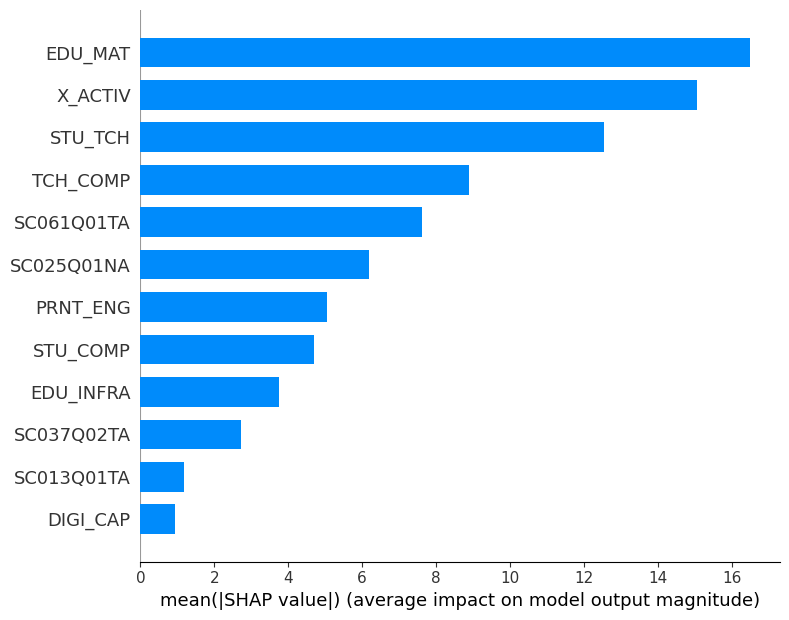


SHAP Summary (beeswarm):


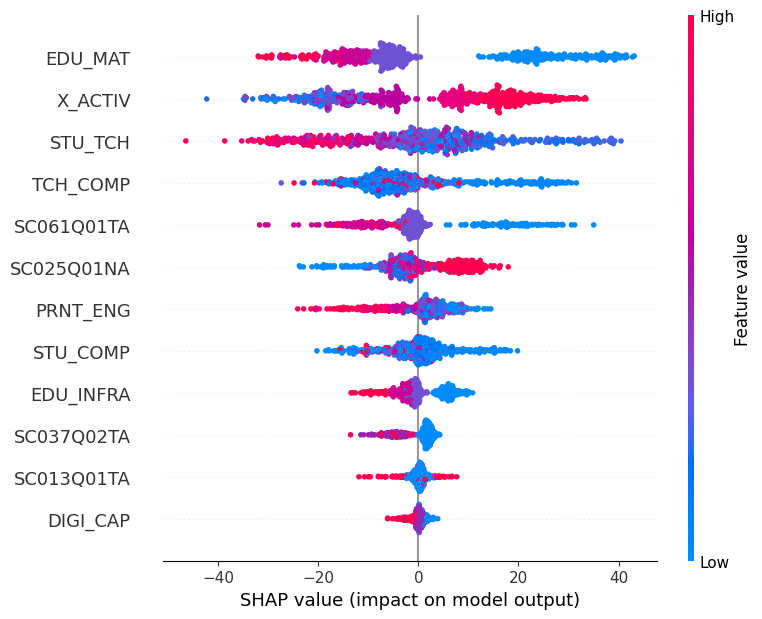


Top SHAP features:
 EDU_MAT       16.481012
X_ACTIV       15.065421
STU_TCH       12.536830
TCH_COMP       8.900317
SC061Q01TA     7.619764
SC025Q01NA     6.178068
PRNT_ENG       5.042863
STU_COMP       4.697222
EDU_INFRA      3.753050
SC037Q02TA     2.707945
SC013Q01TA     1.175159
DIGI_CAP       0.924976
Name: mean_abs_shap, dtype: float32

Top permutation importances:
        feature  importance_mean  importance_std
7      STU_TCH        10.104418        0.874711
9     TCH_COMP         8.166729        0.644683
4      EDU_MAT         7.948878        1.420695
10     X_ACTIV         6.722331        0.871108
2   SC061Q01TA         4.415988        0.481412
11    PRNT_ENG         3.162597        0.424463
8     STU_COMP         3.007660        0.553256
3   SC025Q01NA         1.197451        0.229952
0   SC013Q01TA         0.707416        0.106949
5    EDU_INFRA         0.430378        0.242162
1   SC037Q02TA         0.338986        0.146908
6     DIGI_CAP         0.265529        0.085786


split,test,train,total,train_pct,test_pct
stratum,,,,,
BRN__2018,11,44,55,80.000000,20.000000
BRN__2022,11,43,54,79.629630,20.370370
IDN__2018,79,318,397,80.100756,19.899244
IDN__2022,82,328,410,80.000000,20.000000
KHM__2022,37,146,183,79.781421,20.218579
MYS__2018,38,153,191,80.104712,19.895288
MYS__2022,40,159,199,79.899497,20.100503
PHL__2018,37,150,187,80.213904,19.786096
PHL__2022,38,150,188,79.787234,20.212766


[I 2026-09-28 21:48:41,962] A new study created in memory with name: no-name-6438b932-9a97-45c7-9b03-e0f6916536b9
[I 2026-09-28 21:48:42,780] Trial 0 finished with value: 53.37553794592654 and parameters: {'n_estimators': 637, 'learning_rate': 0.044635901521768134, 'max_depth': 8, 'min_child_weight': 12.374511199743695, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_lambda': 0.01555019165426488, 'reg_alpha': 2.1423021757741068}. Best is trial 0 with value: 53.37553794592654.
[I 2026-09-28 21:48:43,195] Trial 1 finished with value: 51.383224189818286 and parameters: {'n_estimators': 841, 'learning_rate': 0.025529516046973785, 'max_depth': 3, 'min_child_weight': 19.428287191077892, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'reg_lambda': 0.039829941698924086, 'reg_alpha': 0.0008260808399079611}. Best is trial 1 with value: 51.383224189818286.
[I 2026-09-28 21:48:43,804] Trial 2 finished with value: 50.88804492444674 and paramete


Best params: {'n_estimators': 1158, 'learning_rate': 0.006444355772468514, 'max_depth': 7, 'min_child_weight': 7.571048873783722, 'subsample': 0.7963118290418648, 'colsample_bytree': 0.6572422788479485, 'reg_lambda': 15.868483071109846, 'reg_alpha': 0.04491349472016808, 'objective': 'reg:squarederror', 'eval_metric': 'rmse', 'n_jobs': 2, 'tree_method': 'hist', 'random_state': 42}

Untouched-test MAE: 37.019 | RMSE: 46.345 | R^2: 0.623

SHAP Summary (mean absolute contribution):


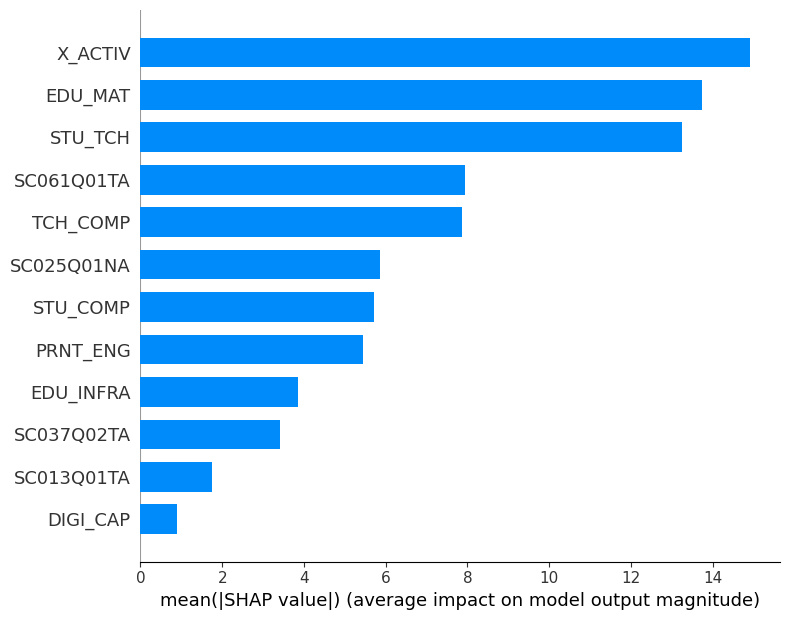


SHAP Summary (beeswarm):


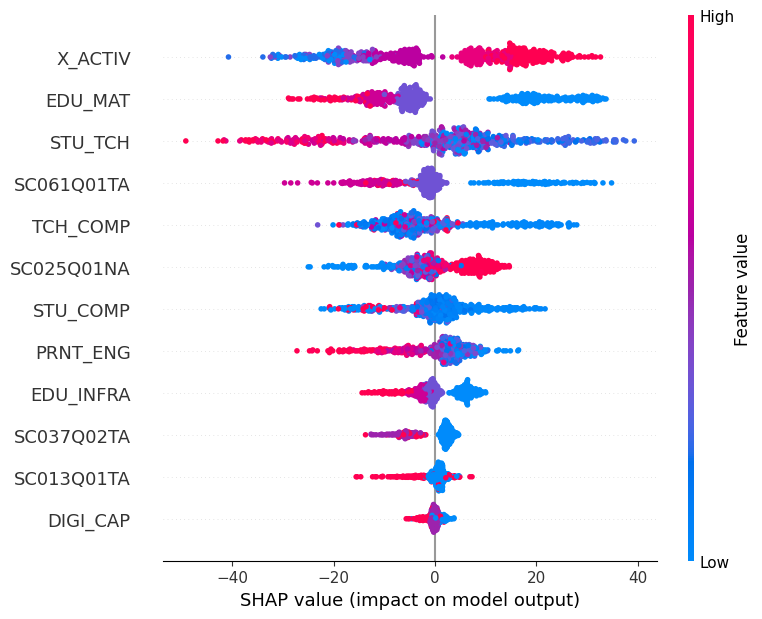


Top SHAP features:
 X_ACTIV       14.905085
EDU_MAT       13.738194
STU_TCH       13.257650
SC061Q01TA     7.947555
TCH_COMP       7.861057
SC025Q01NA     5.862817
STU_COMP       5.722474
PRNT_ENG       5.440727
EDU_INFRA      3.850758
SC037Q02TA     3.411418
SC013Q01TA     1.740022
DIGI_CAP       0.900671
Name: mean_abs_shap, dtype: float32

Top permutation importances:
        feature  importance_mean  importance_std
7      STU_TCH         9.857488        0.849655
10     X_ACTIV         6.672720        0.686485
9     TCH_COMP         6.505006        0.486260
4      EDU_MAT         5.633208        1.041981
2   SC061Q01TA         4.705760        0.589592
11    PRNT_ENG         3.336996        0.428837
8     STU_COMP         3.292442        0.588182
3   SC025Q01NA         1.111692        0.239893
0   SC013Q01TA         0.877714        0.185106
5    EDU_INFRA         0.485215        0.268559
1   SC037Q02TA         0.380170        0.150502
6     DIGI_CAP         0.246225        0.086101


split,test,train,total,train_pct,test_pct
stratum,,,,,
BRN__2018,11,44,55,80.000000,20.000000
BRN__2022,11,43,54,79.629630,20.370370
IDN__2018,79,318,397,80.100756,19.899244
IDN__2022,82,328,410,80.000000,20.000000
KHM__2022,37,146,183,79.781421,20.218579
MYS__2018,38,153,191,80.104712,19.895288
MYS__2022,40,159,199,79.899497,20.100503
PHL__2018,37,150,187,80.213904,19.786096
PHL__2022,38,150,188,79.787234,20.212766


[I 2026-09-28 21:50:49,047] A new study created in memory with name: no-name-2c835c7a-2dcc-4b32-bcc0-c842afdf3434
[I 2026-09-28 21:50:49,820] Trial 0 finished with value: 57.59792211688065 and parameters: {'n_estimators': 637, 'learning_rate': 0.044635901521768134, 'max_depth': 8, 'min_child_weight': 12.374511199743695, 'subsample': 0.6624074561769746, 'colsample_bytree': 0.662397808134481, 'reg_lambda': 0.01555019165426488, 'reg_alpha': 2.1423021757741068}. Best is trial 0 with value: 57.59792211688065.
[I 2026-09-28 21:50:50,210] Trial 1 finished with value: 55.98431875150391 and parameters: {'n_estimators': 841, 'learning_rate': 0.025529516046973785, 'max_depth': 3, 'min_child_weight': 19.428287191077892, 'subsample': 0.9329770563201687, 'colsample_bytree': 0.6849356442713105, 'reg_lambda': 0.039829941698924086, 'reg_alpha': 0.0008260808399079611}. Best is trial 1 with value: 55.98431875150391.
[I 2026-09-28 21:50:50,784] Trial 2 finished with value: 55.38341413907074 and parameters


Best params: {'n_estimators': 1097, 'learning_rate': 0.006259792686051076, 'max_depth': 8, 'min_child_weight': 2.9840157603953683, 'subsample': 0.8616598898097168, 'colsample_bytree': 0.7383031370884041, 'reg_lambda': 16.956804638145858, 'reg_alpha': 0.8113974804042936, 'objective': 'reg:squarederror', 'eval_metric': 'rmse', 'n_jobs': 2, 'tree_method': 'hist', 'random_state': 42}

Untouched-test MAE: 39.377 | RMSE: 50.735 | R^2: 0.635

SHAP Summary (mean absolute contribution):


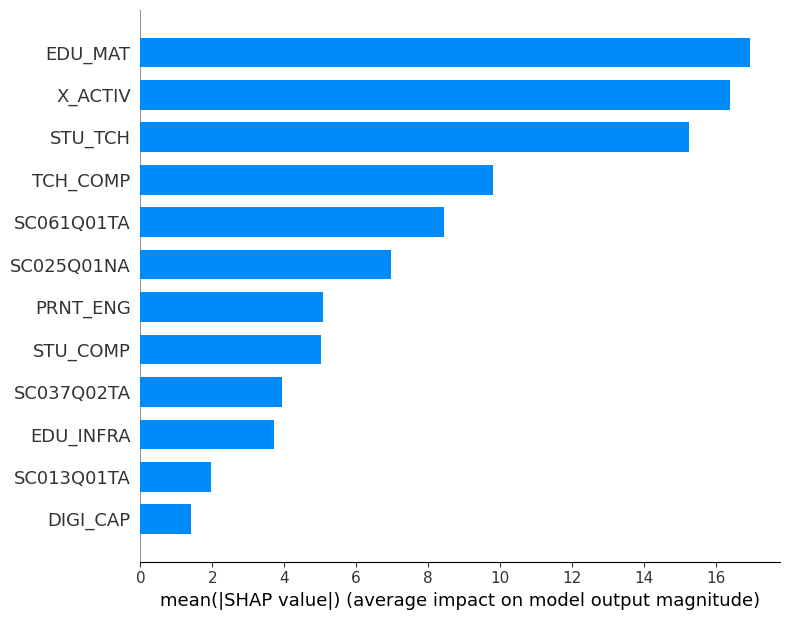


SHAP Summary (beeswarm):


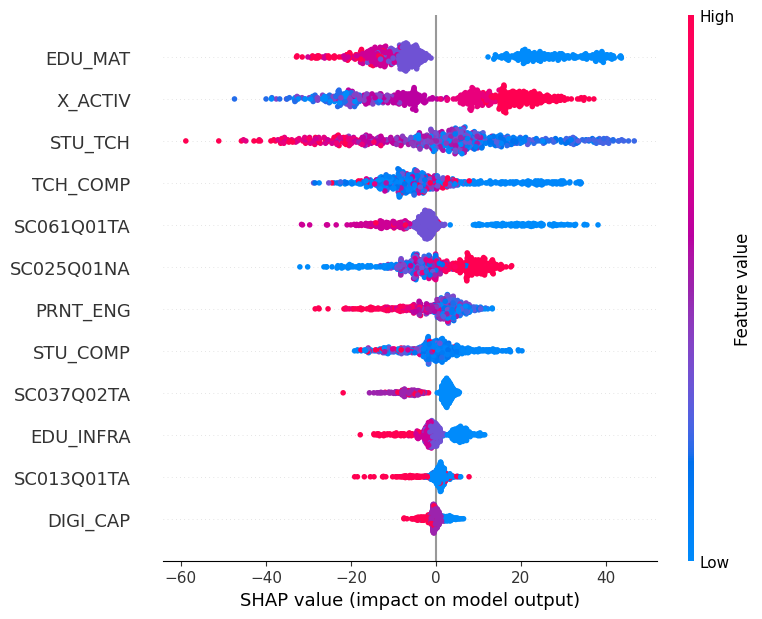


Top SHAP features:
 EDU_MAT       16.936165
X_ACTIV       16.402840
STU_TCH       15.239523
TCH_COMP       9.795597
SC061Q01TA     8.429615
SC025Q01NA     6.980001
PRNT_ENG       5.076210
STU_COMP       5.025254
SC037Q02TA     3.935203
EDU_INFRA      3.717494
SC013Q01TA     1.972550
DIGI_CAP       1.398346
Name: mean_abs_shap, dtype: float32

Top permutation importances:
        feature  importance_mean  importance_std
7      STU_TCH        12.669605        0.947746
9     TCH_COMP         9.009731        0.662939
4      EDU_MAT         7.859610        1.302697
10     X_ACTIV         7.609770        0.697744
2   SC061Q01TA         4.897112        0.641937
11    PRNT_ENG         3.595128        0.494890
8     STU_COMP         3.300128        0.513824
3   SC025Q01NA         1.567147        0.346953
0   SC013Q01TA         0.937195        0.205516
1   SC037Q02TA         0.490693        0.242329
5    EDU_INFRA         0.479657        0.280720
6     DIGI_CAP         0.413317        0.123955


,mae,rmse,r2
READ,40.033776,50.328435,0.604150
SCIE,37.018593,46.344567,0.622742
MATH,39.376618,50.734869,0.634620


In [23]:
combined_id_cols = [
    "CNT", "CNT_x", "CNT_y", "CNTSCHID", "CNTRYID", "ADMINMODE",
    "SC011Q01TA", "SC012Q01TA", "SC012Q02TA", "SC012Q03TA",
    "SC012Q04TA", "SC012Q05TA", "SC012Q06TA",
    "SC042Q01TA", "SC042Q02TA", "YEAR", "EXT_FUND",
]
combined_meta_cols = ["CNT", "CNT_x", "CNT_y", "CNTSCHID", "CNTRYID", "ADMINMODE", "YEAR"]

combined_targets = {"READ": "READ_school_weighted",
                    "SCIE": "SCIE_school_weighted",
                    "MATH": "MATH_school_weighted"}

combined_results = {
    domain: train_xgb_and_shap_optuna(df=df_merged_combined, target_col=target_col,
                                      id_cols=combined_id_cols, meta_cols=combined_meta_cols, n_trials=100)
    for domain, target_col in combined_targets.items()
}
combined_read_results = combined_results["READ"]
combined_scie_results = combined_results["SCIE"]
combined_math_results = combined_results["MATH"]

pd.DataFrame({d: r["metrics"] for d, r in combined_results.items()}).T

#### 2. SHAP feature summaries from the main combined-years models



In [26]:
combined_shap_summary = pd.concat(
    [combined_results[d]["shap_importance"].rename(f"{d}_mean_abs_shap") for d in combined_targets], axis=1
).fillna(0)
combined_shap_summary["mean_across_domains"] = combined_shap_summary.mean(axis=1)
combined_shap_summary = combined_shap_summary.sort_values("mean_across_domains", ascending=False)
combined_shap_summary.head(30)

,READ_mean_abs_shap,SCIE_mean_abs_shap,MATH_mean_abs_shap,mean_across_domains
EDU_MAT,16.481012,13.738194,16.936165,15.718457
X_ACTIV,15.065421,14.905085,16.402840,15.457782
STU_TCH,12.536830,13.257650,15.239523,13.678001
TCH_COMP,8.900317,7.861057,9.795597,8.852324
SC061Q01TA,7.619764,7.947555,8.429615,7.998978
SC025Q01NA,6.178068,5.862817,6.980001,6.340295
PRNT_ENG,5.042863,5.440727,5.076210,5.186600
STU_COMP,4.697222,5.722474,5.025254,5.148316
EDU_INFRA,3.753050,3.850758,3.717494,3.773767
SC037Q02TA,2.707945,3.411418,3.935203,3.351522


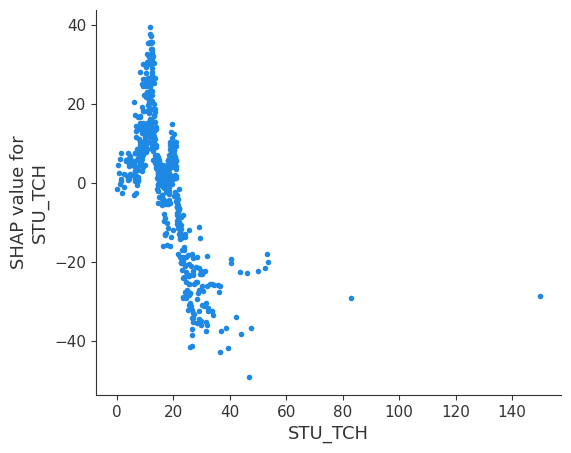

<Figure size 640x480 with 0 Axes>

In [60]:
shap.dependence_plot(
    "STU_TCH",
    combined_scie_results["shap_df"].values,
    combined_scie_results["X_shap"],
    interaction_index=None
)

plt.tight_layout()
plt.show()

#### 4. Counterfactual and actionable recourse analysis

Counterfactuals now reuse the trained combined-years XGBoost result. Change `active_results` to `combined_read_results`, `combined_scie_results`, or `combined_math_results` depending on which domain you want to analyze. Math domain is used as a proxy for all three.


Integer-feasibility rule: among mutable features, only `SC025Q01NA`, `PRNT_ENG`, `TCH_COMP`, `STU_COMP`, and `STU_TCH` are allowed to remain continuous. All other mutable features are rounded and checked as integer-valued variables before prediction and reporting.


In [ ]:
# Configuration
active_domain = "MATH"                 # "READ" | "SCIE" | "MATH"
source_country = "PHL"
active_target_year = 2022              # change to 2018 for the 2018 benchmark target

asean_countries = ["BRN", "KHM", "IDN", "LAO", "MYS", "MMR", "PHL", "SGP", "THA", "VNM", "TLS"]
benchmark_config = {
    # name              countries           exclude PHL from the target group?
    "ASEAN average":   {"countries": asean_countries, "exclude_source": True},
    "Indonesia (IDN)": {"countries": ["IDN"],         "exclude_source": False},
    "Singapore (SGP)": {"countries": ["SGP"],         "exclude_source": False},
}

# Features that may be changed by recourse (everything else is immutable).
mutable_features_config = ["SC061Q01TA", "EDU_MAT", "EDU_INFRA", "DIGI_CAP", "STU_TCH", "STU_COMP",
                           "TCH_COMP", "X_ACTIV", "PRNT_ENG", "SC025Q01NA", "SC037Q02TA"]
# Only these five may stay continuous; every other mutable feature is integer-valued.
continuous_mutable_config = ["SC025Q01NA", "PRNT_ENG", "TCH_COMP", "STU_COMP", "STU_TCH"]

# Feasible range = training [1%, 99%] quantiles ∩ measurement scale.
range_quantiles = (0.01, 0.99)
domain_ranges = {
    "EXT_FUND": [0, 100], "EDU_MAT": [1, 4], "EDU_INFRA": [1, 4], "DIGI_CAP": [1, 4],
    "STU_TCH": [0, 200], "STU_COMP": [0, 400], "TCH_COMP": [0, 200], "X_ACTIV": [0, 6], "PRNT_ENG": [0, 100],
}

# Group-recourse optimizer settings 
recourse_settings = dict(n_iter=5000, n_runs=1, n_solutions=1, max_features_changed=12,
                         random_state=42, penalty_weight=1.0)

In [ ]:
# Load the already-trained model and define feature roles
active_results = combined_results[active_domain]
model = active_results["model"]
X_train, X_test = active_results["X_train"], active_results["X_test"]
y_train, y_test = active_results["y_train"], active_results["y_test"]
meta_train, meta_test = active_results["meta_train"], active_results["meta_test"]

group_col = _pick_country_col(meta_test)
if group_col is None:
    raise ValueError("No country column found in metadata. Check combined_meta_cols.")

mutable_features = [c for c in mutable_features_config if c in X_train.columns]
immutable_features = [c for c in X_train.columns if c not in mutable_features]
continuous_mutable_features = [c for c in continuous_mutable_config if c in mutable_features]
integer_like_features = [c for c in mutable_features if c not in continuous_mutable_features]

print(f"Counterfactual domain: {active_domain} | group column: {group_col}")
print("Continuous mutable features:     ", continuous_mutable_features)
print("Integer-constrained mutable features:", integer_like_features)
print("Number of immutable features:", len(immutable_features))

Counterfactual domain: MATH | group column: CNT_x
Continuous mutable features:      ['SC025Q01NA', 'PRNT_ENG', 'TCH_COMP', 'STU_COMP', 'STU_TCH']
Integer-constrained mutable features: ['SC061Q01TA', 'EDU_MAT', 'EDU_INFRA', 'DIGI_CAP', 'X_ACTIV', 'SC037Q02TA']
Number of immutable features: 1


In [ ]:
#  Feasible action space, constraint projection, and change summaries
def build_permitted_ranges(X_reference, mutable_features, integer_like_features,
                           lower_q=0.01, upper_q=0.99, domain_ranges=None):
    permitted_ranges = {}
    for col in mutable_features:
        lo, hi = X_reference[col].quantile(lower_q), X_reference[col].quantile(upper_q)
        if domain_ranges and col in domain_ranges:
            lo, hi = max(lo, domain_ranges[col][0]), min(hi, domain_ranges[col][1])
        if col in integer_like_features:                       # integer-feasible bounds
            int_lo, int_hi = np.ceil(lo), np.floor(hi)
            lo, hi = (int_lo, int_hi) if int_lo <= int_hi else (np.round(lo), np.round(hi))
        permitted_ranges[col] = [float(lo), float(hi)]
    return permitted_ranges


def enforce_constraints(X_cf, permitted_ranges, integer_like_features=None):
    # 1) clip every mutable feature to its range; 2) round integer features and clip again.
    X_cf = X_cf.copy()
    for col, (lo, hi) in permitted_ranges.items():
        if col in X_cf.columns:
            X_cf[col] = X_cf[col].clip(lo, hi)
    for col in (integer_like_features or []):
        if col in X_cf.columns and col in permitted_ranges:
            X_cf[col] = X_cf[col].round().clip(*permitted_ranges[col])
    return X_cf


def check_integer_mutable_constraints(X_cf, integer_like_features, label="counterfactual"):
    rows = []
    for col in integer_like_features:
        if col not in X_cf.columns:
            continue
        vals = X_cf[col].dropna()
        max_dec = float((vals - vals.round()).abs().max()) if len(vals) else 0.0
        rows.append({"scenario": label, "feature": col, "integer_constrained": True,
                     "max_abs_decimal_part": max_dec, "passes_integer_check": max_dec < 1e-9,
                     "min_value": float(vals.min()) if len(vals) else np.nan,
                     "max_value": float(vals.max()) if len(vals) else np.nan})
    return pd.DataFrame(rows)


def summarize_needed_changes(original, counterfactual, mutable_features, label="counterfactual"):
    # Per-variable changes for ONE instance (used by DiCE).
    before = original.iloc[0] if isinstance(original, pd.DataFrame) else original
    after = counterfactual.iloc[0] if isinstance(counterfactual, pd.DataFrame) else counterfactual
    rows = [{"scenario": label, "feature": c, "current_value": before[c],
             "target_counterfactual_value": after[c], "needed_change": after[c] - before[c],
             "absolute_change": abs(after[c] - before[c])}
            for c in mutable_features
            if c in before.index and c in after.index and pd.notna(after[c] - before[c]) and abs(after[c] - before[c]) > 1e-9]
    return pd.DataFrame(rows, columns=["scenario", "feature", "current_value", "target_counterfactual_value",
                                       "needed_change", "absolute_change"]).sort_values("absolute_change", ascending=False)


def summarize_group_changes(X_original, X_cf, mutable_features, label="group_counterfactual"):
    # Mean/median changes for a GROUP of schools.
    rows = [{"scenario": label, "feature": c,
             "current_mean": X_original[c].mean(), "counterfactual_mean": X_cf[c].mean(),
             "needed_mean_change": X_cf[c].mean() - X_original[c].mean(),
             "current_median": X_original[c].median(), "counterfactual_median": X_cf[c].median(),
             "needed_median_change": X_cf[c].median() - X_original[c].median()}
            for c in mutable_features]
    return pd.DataFrame(rows).sort_values("needed_mean_change", key=lambda s: s.abs(), ascending=False)


permitted_ranges = build_permitted_ranges(X_train, mutable_features, integer_like_features,
                                          *range_quantiles, domain_ranges=domain_ranges)
pd.DataFrame(permitted_ranges, index=["lower", "upper"]).T

,lower,upper
SC061Q01TA,1.00000,4.000000
EDU_MAT,1.00000,4.000000
EDU_INFRA,1.00000,4.000000
DIGI_CAP,1.00000,4.000000
STU_TCH,2.41726,44.267295
STU_COMP,0.00000,91.980000
TCH_COMP,0.00000,61.398317
X_ACTIV,0.00000,6.000000
PRNT_ENG,0.87750,100.000000
SC025Q01NA,0.00000,100.000000


In [ ]:
# PHL group and benchmark targets (held-out test set, benchmark year)
def filter_by_year(X, y, meta, year_col="YEAR", year=None):
    if year is None or year_col not in meta.columns:
        return X.copy(), y.copy(), meta.copy()
    idx = meta[meta[year_col] == year].index
    return X.loc[idx].copy(), y.loc[idx].copy(), meta.loc[idx].copy()


def get_group_data(X, y, meta, group_col, group_code):
    idx = meta[meta[group_col] == group_code].index
    return X.loc[idx].copy(), y.loc[idx].copy(), meta.loc[idx].copy()


def get_multi_country_data(X, y, meta, group_col, country_codes, exclude_country=None):
    codes = [c for c in country_codes if c != exclude_country]
    available = set(meta[group_col].dropna().unique())
    valid_codes = [c for c in codes if c in available]
    missing_codes = [c for c in codes if c not in available]
    idx = meta[meta[group_col].isin(valid_codes)].index
    return X.loc[idx].copy(), y.loc[idx].copy(), meta.loc[idx].copy(), valid_codes, missing_codes


def get_country_mean_predictions(model, X, meta, group_col):
    # Target = mean of country means → each country weighted equally.
    country_means = (pd.DataFrame({"country": meta[group_col], "predicted_score": model.predict(X)})
                     .groupby("country", as_index=False)["predicted_score"].mean()
                     .rename(columns={"predicted_score": "predicted_mean"}).sort_values("country"))
    return float(country_means["predicted_mean"].mean()), country_means


def build_computed_benchmark_target(target_name, countries, exclude_source):
    X_target, _, meta_target, valid_codes, missing_codes = get_multi_country_data(
        X_bench, y_bench, meta_bench, group_col, countries,
        exclude_country=source_country if exclude_source else None)
    if len(X_target) == 0:
        raise ValueError(f"No rows for target {target_name}. Valid: {valid_codes}; missing: {missing_codes}")
    target_mean, country_means = get_country_mean_predictions(model, X_target, meta_target, group_col)
    return {"target_mean": target_mean, "X_target": X_target, "meta_target": meta_target,
            "country_means": country_means, "valid_codes": valid_codes, "missing_codes": missing_codes}


# Benchmark sample = held-out test schools in the benchmark year
X_bench, y_bench, meta_bench = filter_by_year(X_test, y_test, meta_test, "YEAR", active_target_year)

# Source group (PHL)
X_phl, y_phl, meta_phl = get_group_data(X_bench, y_bench, meta_bench, group_col, source_country)
if len(X_phl) == 0:
    raise ValueError(f"Missing rows for source country {source_country} in the selected benchmark sample.")
phl_current_mean = float(model.predict(X_phl).mean())

# Benchmark targets
benchmark_targets = {name: build_computed_benchmark_target(name, **cfg) for name, cfg in benchmark_config.items()}

print(f"{source_country} predicted mean ({active_target_year}):", phl_current_mean)
for name, cfg in benchmark_targets.items():
    print(f"{name}: target mean = {cfg['target_mean']:.2f} | used = {cfg['valid_codes']} | missing = {cfg['missing_codes']}")

PHL predicted mean (2022): 369.55865478515625
ASEAN average: target mean = 423.29 | used = ['BRN', 'KHM', 'IDN', 'MYS', 'SGP', 'THA', 'VNM'] | missing = ['LAO', 'MMR', 'TLS']
Indonesia (IDN): target mean = 398.79 | used = ['IDN'] | missing = []
Singapore (SGP): target mean = 541.30 | used = ['SGP'] | missing = []


##### Group counterfactuals: ASEAN average, Indonesia, and Singapore benchmarks



In [ ]:
# quantile transfer, then feasibility projection
def quantile_transfer_group_average_target(X_source, X_target, meta_target, group_col, mutable_features,
                                           permitted_ranges, integer_like_features=None):
    X_cf = X_source.copy()
    target_countries = sorted(meta_target[group_col].dropna().unique())
    if not target_countries:
        raise ValueError("No target countries are available for quantile transfer.")

    for col in mutable_features:
        if col not in X_source.columns or col not in X_target.columns:
            continue
        source_rank = X_source[col].rank(method="average", pct=True).values
        country_quantiles = [np.quantile(vals, source_rank)
                             for country in target_countries
                             if len(vals := X_target.loc[meta_target[group_col] == country, col].dropna().values)]
        if country_quantiles:
            X_cf[col] = np.mean(country_quantiles, axis=0)
    return enforce_constraints(X_cf, permitted_ranges, integer_like_features)


# Step 3 — run for each benchmark
distribution_transfer_results = {}
for benchmark_name, cfg in benchmark_targets.items():
    X_cf_distribution = quantile_transfer_group_average_target(
        X_phl, cfg["X_target"], cfg["meta_target"], group_col, mutable_features, permitted_ranges, integer_like_features)
    distribution_pred = model.predict(X_cf_distribution)
    needed_changes = summarize_group_changes(X_phl, X_cf_distribution, mutable_features,
                                             label=f"PHL to {benchmark_name} distribution transfer")
    distribution_transfer_results[benchmark_name] = {"X_cf": X_cf_distribution, "pred": distribution_pred,
                                                     "needed_changes": needed_changes}

    print(f"\nPHL counterfactual mean if mutable features resembled {benchmark_name}: {distribution_pred.mean():.2f}")
    print(f"Gain: {distribution_pred.mean() - phl_current_mean:+.2f} | "
          f"Remaining target gap: {cfg['target_mean'] - distribution_pred.mean():.2f}")
    display(needed_changes)

# Backward-compatible ASEAN aliases
asean_target_mean = benchmark_targets["ASEAN average"]["target_mean"]
asean_country_means = benchmark_targets["ASEAN average"]["country_means"]
valid_asean_codes = benchmark_targets["ASEAN average"]["valid_codes"]
missing_asean_codes = benchmark_targets["ASEAN average"]["missing_codes"]
X_asean = benchmark_targets["ASEAN average"]["X_target"]
meta_asean = benchmark_targets["ASEAN average"]["meta_target"]
X_phl_cf_asean_distribution = distribution_transfer_results["ASEAN average"]["X_cf"]
phl_asean_distribution_pred = distribution_transfer_results["ASEAN average"]["pred"]
asean_distribution_needed_changes = distribution_transfer_results["ASEAN average"]["needed_changes"]


PHL counterfactual mean if mutable features resembled ASEAN average: 400.53
Gain: +30.97 | Remaining target gap: 22.76


,scenario,feature,current_mean,counterfactual_mean,needed_mean_change,current_median,counterfactual_median,needed_median_change
9,PHL to ASEAN average distribution transfer,SC025Q01NA,88.842105,70.309656,-18.532450,100.0000,84.981203,-15.018797
8,PHL to ASEAN average distribution transfer,PRNT_ENG,58.460526,40.058345,-18.402181,51.8750,37.622180,-14.252820
4,PHL to ASEAN average distribution transfer,STU_TCH,32.426818,15.900689,-16.526129,26.8855,15.716806,-11.168694
5,PHL to ASEAN average distribution transfer,STU_COMP,21.228945,6.571809,-14.657136,3.7750,2.986976,-0.788024
6,PHL to ASEAN average distribution transfer,TCH_COMP,3.791158,6.150651,2.359493,1.4557,2.518362,1.062662
7,PHL to ASEAN average distribution transfer,X_ACTIV,2.526316,3.947368,1.421053,2.5000,4.000000,1.500000
1,PHL to ASEAN average distribution transfer,EDU_MAT,2.236842,1.842105,-0.394737,2.0000,2.000000,0.000000
2,PHL to ASEAN average distribution transfer,EDU_INFRA,2.210526,1.921053,-0.289474,2.0000,2.000000,0.000000
3,PHL to ASEAN average distribution transfer,DIGI_CAP,3.342105,3.421053,0.078947,3.0000,3.000000,0.000000
0,PHL to ASEAN average distribution transfer,SC061Q01TA,2.315789,2.315789,0.000000,2.0000,2.000000,0.000000



PHL counterfactual mean if mutable features resembled Indonesia (IDN): 398.46
Gain: +28.90 | Remaining target gap: 0.32


,scenario,feature,current_mean,counterfactual_mean,needed_mean_change,current_median,counterfactual_median,needed_median_change
9,PHL to Indonesia (IDN) distribution transfer,SC025Q01NA,88.842105,51.611496,-37.230609,100.0000,70.000000,-30.000000
8,PHL to Indonesia (IDN) distribution transfer,PRNT_ENG,58.460526,41.176420,-17.284107,51.8750,36.907895,-14.967105
5,PHL to Indonesia (IDN) distribution transfer,STU_COMP,21.228945,4.936186,-16.292759,3.7750,2.964133,-0.810867
4,PHL to Indonesia (IDN) distribution transfer,STU_TCH,32.426818,17.717058,-14.709760,26.8855,17.682687,-9.202813
7,PHL to Indonesia (IDN) distribution transfer,X_ACTIV,2.526316,4.289474,1.763158,2.5000,4.500000,2.000000
6,PHL to Indonesia (IDN) distribution transfer,TCH_COMP,3.791158,4.361667,0.570509,1.4557,2.340271,0.884571
0,PHL to Indonesia (IDN) distribution transfer,SC061Q01TA,2.315789,1.921053,-0.394737,2.0000,2.000000,0.000000
2,PHL to Indonesia (IDN) distribution transfer,EDU_INFRA,2.210526,1.921053,-0.289474,2.0000,2.000000,0.000000
1,PHL to Indonesia (IDN) distribution transfer,EDU_MAT,2.236842,2.026316,-0.210526,2.0000,2.000000,0.000000
3,PHL to Indonesia (IDN) distribution transfer,DIGI_CAP,3.342105,3.394737,0.052632,3.0000,3.000000,0.000000



PHL counterfactual mean if mutable features resembled Singapore (SGP): 543.34
Gain: +173.78 | Remaining target gap: -2.04


,scenario,feature,current_mean,counterfactual_mean,needed_mean_change,current_median,counterfactual_median,needed_median_change
8,PHL to Singapore (SGP) distribution transfer,PRNT_ENG,58.460526,29.691482,-28.769044,51.8750,29.355263,-22.519737
4,PHL to Singapore (SGP) distribution transfer,STU_TCH,32.426818,11.838772,-20.588046,26.8855,12.199479,-14.686021
5,PHL to Singapore (SGP) distribution transfer,STU_COMP,21.228945,1.030525,-20.198420,3.7750,0.952195,-2.822805
7,PHL to Singapore (SGP) distribution transfer,X_ACTIV,2.526316,5.394737,2.868421,2.5000,5.500000,3.000000
6,PHL to Singapore (SGP) distribution transfer,TCH_COMP,3.791158,1.037635,-2.753523,1.4557,0.779484,-0.676216
9,PHL to Singapore (SGP) distribution transfer,SC025Q01NA,88.842105,86.199446,-2.642659,100.0000,100.000000,0.000000
1,PHL to Singapore (SGP) distribution transfer,EDU_MAT,2.236842,1.184211,-1.052632,2.0000,1.000000,-1.000000
2,PHL to Singapore (SGP) distribution transfer,EDU_INFRA,2.210526,1.263158,-0.947368,2.0000,1.000000,-1.000000
0,PHL to Singapore (SGP) distribution transfer,SC061Q01TA,2.315789,1.921053,-0.394737,2.0000,2.000000,0.000000
10,PHL to Singapore (SGP) distribution transfer,SC037Q02TA,1.447368,1.052632,-0.394737,1.0000,1.000000,0.000000


##### 4.3 Group actionable recourse: Optuna/TPE optimization for common variable changes needed to reach ASEAN, Indonesia, and Singapore targets

**Steps in this section:** 

Objective:  **L(Δ) = max(0, T − mean ŷ(X + Δ)) + λ · Σⱼ |Δⱼ| / (uⱼ − lⱼ) + P**

| Step | Function | Does |
|---|---|---|
| 1 | `suggest_intervention` | TPE picks, per mutable feature, whether to change it and its new group mean |
| 2 | `apply_intervention` | shifts every PHL school by the same Δⱼ, then `enforce_constraints` |
| 3 | `score_intervention` | predicts the group mean and computes gap, cost C(Δ), penalty P, loss L |
| 4 | `group_recourse_optuna_search` | runs TPE over steps 1–3; rebuilds the best trial |
| 5 | `collect_top_group_recourse_solutions` | repeats step 4 over seeds, de-duplicates, ranks |
| 6 | run loop | one optimization per benchmark  |

In [ ]:
optuna.logging.set_verbosity(optuna.logging.WARNING)


#  search space for one trial → {feature: proposed new group mean}
def suggest_intervention(trial, X_group, mutable_features, permitted_ranges, integer_feature_set):
    proposed = {}
    for col in mutable_features:
        change_flag = trial.suggest_categorical(f"change__{col}", [0, 1])
        lo, hi = permitted_ranges[col]
        if col in integer_feature_set:
            int_lo, int_hi = int(np.ceil(lo)), int(np.floor(hi))
            new_mean = (float(trial.suggest_int(f"mean__{col}", int_lo, int_hi)) if int_lo <= int_hi
                        else float(np.round(np.clip(X_group[col].mean(), lo, hi))))
        else:
            new_mean = trial.suggest_float(f"mean__{col}", float(lo), float(hi))
        if change_flag:
            proposed[col] = new_mean
    return proposed


#  common shift Δ_j for every school, then feasibility projection
def apply_intervention(X_group, proposed_means, permitted_ranges, integer_like_features):
    X_cf = X_group.copy()
    deltas = {col: new_mean - X_group[col].mean() for col, new_mean in proposed_means.items()}
    for col, delta in deltas.items():
        X_cf[col] = X_cf[col] + delta
    return enforce_constraints(X_cf, permitted_ranges, integer_like_features), deltas


# loss L(Δ) = gap + λ·C(Δ) + P
def score_intervention(model, X_cf, deltas, base_mean, target_mean, permitted_ranges,
                       penalty_weight=1.0, max_features_changed=12, invalid_penalty=1e6):
    normalized_cost = sum(abs(d) / max(permitted_ranges[c][1] - permitted_ranges[c][0], 1e-9)
                          for c, d in deltas.items())
    n_changed = len(deltas)
    feature_count_penalty = 0.0
    if n_changed == 0:
        feature_count_penalty += invalid_penalty
    if n_changed > max_features_changed:
        feature_count_penalty += invalid_penalty + 1000.0 * (n_changed - max_features_changed)

    cf_mean = model.predict(X_cf).mean()
    target_gap = max(0.0, target_mean - cf_mean)
    return {"objective": target_gap + penalty_weight * normalized_cost + feature_count_penalty,
            "cf_mean": cf_mean, "gain": cf_mean - base_mean, "target_gap": target_gap,
            "normalized_cost": normalized_cost, "feature_count_penalty": feature_count_penalty,
            "changed_features": list(deltas), "deltas": deltas, "X_cf": X_cf.copy()}


#  Optuna/TPE over steps 1–3
def group_recourse_optuna_search(model, X_group, target_mean, mutable_features, permitted_ranges,
                                 integer_like_features=None, n_trials=5000, max_features_changed=12,
                                 random_state=42, penalty_weight=1.0):
    integer_feature_set = set(integer_like_features or [])
    base_mean = model.predict(X_group).mean()

    def evaluate(trial):
        proposed = suggest_intervention(trial, X_group, mutable_features, permitted_ranges, integer_feature_set)
        X_cf, deltas = apply_intervention(X_group, proposed, permitted_ranges, integer_like_features)
        return score_intervention(model, X_cf, deltas, base_mean, target_mean, permitted_ranges,
                                  penalty_weight, max_features_changed)

    def objective(trial):
        result = evaluate(trial)
        for key in ("cf_mean", "gain", "changed_features", "normalized_cost", "target_gap", "feature_count_penalty"):
            trial.set_user_attr(key, result[key])
        return result["objective"]

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=random_state))
    study.optimize(objective, n_trials=n_trials, show_progress_bar=False)

    best = evaluate(optuna.trial.FixedTrial(study.best_trial.params))    # rebuild best candidate
    best.update(study=study, best_trial_number=study.best_trial.number)
    return best


def group_recourse_random_search(model, X_group, target_mean, mutable_features, permitted_ranges,
                                 integer_like_features=None, n_iter=5000, **kwargs):
    # Backward-compatible alias (the original random search was replaced by Optuna/TPE).
    return group_recourse_optuna_search(model, X_group, target_mean, mutable_features, permitted_ranges,
                                        integer_like_features, n_trials=n_iter, **kwargs)

In [ ]:
# repeat over seeds, de-duplicate identical solutions, rank
def _recourse_candidate(result, X_group, target_mean, baseline_mean, seed):
    change_table = summarize_group_changes(X_group, result["X_cf"], mutable_features,
                                           label=f"Optuna/TPE group recourse seed {seed}")
    changed_only = change_table[change_table["needed_mean_change"].abs() > 1e-9].copy()
    return {"seed": seed, "optimizer": "Optuna TPE", "objective": result["objective"],
            "predicted_mean": result["cf_mean"], "gain": result["cf_mean"] - baseline_mean,
            "remaining_gap": target_mean - result["cf_mean"], "normalized_cost": result["normalized_cost"],
            "target_gap": result["target_gap"],
            "changed_features": ", ".join(changed_only["feature"]) if len(changed_only) else "No changed features",
            "X_cf": result["X_cf"], "change_table": changed_only,
            "signature": tuple(np.round(result["X_cf"][mutable_features].mean().values, 6)),
            "study": result["study"], "best_trial_number": result["best_trial_number"]}


def collect_top_group_recourse_solutions(model, X_group, target_mean, mutable_features, permitted_ranges,
                                         integer_like_features=None, n_solutions=1, n_runs=1, n_iter=5000,
                                         max_features_changed=12, random_state=42, penalty_weight=1.0):
    baseline_mean = model.predict(X_group).mean()
    candidates = []
    for seed in range(random_state, random_state + n_runs):
        result = group_recourse_optuna_search(model, X_group, target_mean, mutable_features, permitted_ranges,
                                              integer_like_features, n_trials=n_iter,
                                              max_features_changed=max_features_changed,
                                              random_state=seed, penalty_weight=penalty_weight)
        candidates.append(_recourse_candidate(result, X_group, target_mean, baseline_mean, seed))

    unique = {}                                   # keep best objective per distinct solution
    for c in candidates:
        if c["signature"] not in unique or c["objective"] < unique[c["signature"]]["objective"]:
            unique[c["signature"]] = c
    top = sorted(unique.values(), key=lambda c: (c["objective"], -c["predicted_mean"]))[:n_solutions]

    summary_cols = ["seed", "optimizer", "best_trial_number", "objective", "predicted_mean", "gain",
                    "remaining_gap", "normalized_cost", "target_gap", "changed_features"]
    top_summary = pd.DataFrame([{"rank": i, **{k: c[k] for k in summary_cols}} for i, c in enumerate(top, start=1)])
    return top_summary, top

In [ ]:
#  run common-action recourse for each benchmark
group_recourse_results, top5_group_recourse_results, recourse_needed_change_tables = {}, {}, []

for benchmark_name, cfg in benchmark_targets.items():
    target_mean = cfg["target_mean"]
    top_summary, top_solutions = collect_top_group_recourse_solutions(
        model, X_phl, target_mean, mutable_features, permitted_ranges, integer_like_features, **recourse_settings)

    best_solution = top_solutions[0]
    X_cf_recourse = best_solution["X_cf"]

    print(f"\n--- PHL group actionable recourse toward {benchmark_name} (Optuna/TPE) ---")
    display(top_summary)
    print(f"PHL current mean: {phl_current_mean:.2f} | Target: {target_mean:.2f} | "
          f"CF mean: {best_solution['predicted_mean']:.2f} | Gain: {best_solution['gain']:+.2f} | "
          f"Remaining gap: {target_mean - best_solution['predicted_mean']:.2f} | "
          f"Normalized cost: {best_solution['normalized_cost']:.3f}")
    for rank, sol in enumerate(top_solutions, start=1):
        print(f"Needed group-level variable changes, rank {rank}:")
        display(sol["change_table"])
    print("Integer constraint check:")
    display(check_integer_mutable_constraints(X_cf_recourse, integer_like_features,
                                              label=f"PHL Optuna/TPE recourse toward {benchmark_name}"))

    group_recourse_results[benchmark_name] = {
        "optimizer": "Optuna TPE", "objective": best_solution["objective"],
        "cf_mean": best_solution["predicted_mean"], "gain": best_solution["gain"],
        "remaining_gap": target_mean - best_solution["predicted_mean"],
        "normalized_cost": best_solution["normalized_cost"], "changed_features": best_solution["changed_features"],
        "X_cf": X_cf_recourse, "target_mean": target_mean, "recourse_pred": model.predict(X_cf_recourse),
        "needed_changes": best_solution["change_table"], "top5_summary": top_summary, "top5_solutions": top_solutions,
    }
    top5_group_recourse_results[benchmark_name] = {"summary": top_summary, "solutions": top_solutions}
    recourse_needed_change_tables.append(best_solution["change_table"].assign(target=benchmark_name))

recourse_needed_changes_all_targets = pd.concat(recourse_needed_change_tables, ignore_index=True)
recourse_needed_changes_all_targets


--- PHL group actionable recourse toward ASEAN average (Optuna/TPE) ---


,rank,seed,optimizer,best_trial_number,objective,predicted_mean,gain,remaining_gap,normalized_cost,target_gap,changed_features
0,1,42,Optuna TPE,1087,1.404442,423.333496,53.774841,-0.047638,1.404442,0.0,"STU_TCH, STU_COMP, X_ACTIV, SC061Q01TA, PRNT_ENG"


PHL current mean: 369.56 | Target: 423.29 | CF mean: 423.33 | Gain: +53.77 | Remaining gap: -0.05 | Normalized cost: 1.404
Needed group-level variable changes, rank 1:


,scenario,feature,current_mean,counterfactual_mean,needed_mean_change,current_median,counterfactual_median,needed_median_change
4,Optuna/TPE group recourse seed 42,STU_TCH,32.426818,13.685852,-18.740966,26.8855,10.693794,-16.191706
5,Optuna/TPE group recourse seed 42,STU_COMP,21.228945,13.193682,-8.035263,3.7750,3.775000,0.000000
7,Optuna/TPE group recourse seed 42,X_ACTIV,2.526316,5.078947,2.552632,2.5000,5.500000,3.000000
0,Optuna/TPE group recourse seed 42,SC061Q01TA,2.315789,1.500000,-0.815789,2.0000,1.000000,-1.000000
8,Optuna/TPE group recourse seed 42,PRNT_ENG,58.460526,58.483618,0.023092,51.8750,51.875000,0.000000


Integer constraint check:


...

PHL current mean: 369.56 | Target: 541.30 | CF mean: 451.47 | Gain: +81.91 | Remaining gap: 89.82 | Normalized cost: 2.780
Needed group-level variable changes, rank 1:


,scenario,feature,current_mean,counterfactual_mean,needed_mean_change,current_median,counterfactual_median,needed_median_change
8,Optuna/TPE group recourse seed 42,PRNT_ENG,58.460526,18.967586,-39.492941,51.8750,5.086120,-46.788880
4,Optuna/TPE group recourse seed 42,STU_TCH,32.426818,14.184043,-18.242776,26.8855,11.267468,-15.618032
5,Optuna/TPE group recourse seed 42,STU_COMP,21.228945,13.962428,-7.266516,3.7750,4.586455,0.811455
7,Optuna/TPE group recourse seed 42,X_ACTIV,2.526316,5.078947,2.552632,2.5000,5.500000,3.000000
9,Optuna/TPE group recourse seed 42,SC025Q01NA,88.842105,91.141519,2.299414,100.0000,100.000000,0.000000
0,Optuna/TPE group recourse seed 42,SC061Q01TA,2.315789,1.500000,-0.815789,2.0000,1.000000,-1.000000
2,Optuna/TPE group recourse seed 42,EDU_INFRA,2.210526,1.552632,-0.657895,2.0000,1.000000,-1.000000
1,Optuna/TPE group recourse seed 42,EDU_MAT,2.236842,1.578947,-0.657895,2.0000,1.000000,-1.000000


Integer constraint check:


,scenario,feature,integer_constrained,max_abs_decimal_part,passes_integer_check,min_value,max_value
0,PHL Optuna/TPE recourse toward Singapore (SGP),SC061Q01TA,True,0.0,True,1.0,3.0
1,PHL Optuna/TPE recourse toward Singapore (SGP),EDU_MAT,True,0.0,True,1.0,3.0
2,PHL Optuna/TPE recourse toward Singapore (SGP),EDU_INFRA,True,0.0,True,1.0,3.0
3,PHL Optuna/TPE recourse toward Singapore (SGP),DIGI_CAP,True,0.0,True,1.0,4.0
4,PHL Optuna/TPE recourse toward Singapore (SGP),X_ACTIV,True,0.0,True,3.0,6.0
5,PHL Optuna/TPE recourse toward Singapore (SGP),SC037Q02TA,True,0.0,True,1.0,3.0


,scenario,feature,current_mean,counterfactual_mean,needed_mean_change,current_median,counterfactual_median,needed_median_change,target
0,Optuna/TPE group recourse seed 42,STU_TCH,32.426818,13.685852,-18.740966,26.8855,10.693794,-16.191706,ASEAN average
1,Optuna/TPE group recourse seed 42,STU_COMP,21.228945,13.193682,-8.035263,3.7750,3.775000,0.000000,ASEAN average
2,Optuna/TPE group recourse seed 42,X_ACTIV,2.526316,5.078947,2.552632,2.5000,5.500000,3.000000,ASEAN average
3,Optuna/TPE group recourse seed 42,SC061Q01TA,2.315789,1.500000,-0.815789,2.0000,1.000000,-1.000000,ASEAN average
4,Optuna/TPE group recourse seed 42,PRNT_ENG,58.460526,58.483618,0.023092,51.8750,51.875000,0.000000,ASEAN average
5,Optuna/TPE group recourse seed 42,STU_TCH,32.426818,21.443453,-10.983365,26.8855,19.279864,-7.605636,Indonesia (IDN)
6,Optuna/TPE group recourse seed 42,STU_COMP,21.228945,13.372634,-7.856311,3.7750,3.963894,0.188894,Indonesia (IDN)
7,Optuna/TPE group recourse seed 42,X_ACTIV,2.526316,4.394737,1.868421,2.5000,4.500000,2.000000,Indonesia (IDN)
8,Optuna/TPE group recourse seed 42,PRNT_ENG,58.460526,58.483618,0.023092,51.8750,51.875000,0.000000,Indonesia (IDN)
9,Optuna/TPE group recourse seed 42,PRNT_ENG,58.460526,18.967586,-39.492941,51.8750,5.086120,-46.788880,Singapore (SGP)


In [37]:
# Archived: original random-search optimizer (kept for reference, not executed)
# def group_recourse_random_search(
#     model,
#     X_group,
#     target_mean,
#     mutable_features,
#     permitted_ranges,
#     integer_like_features=None,
#     n_iter=7000,
#     max_features_changed=12,
#     random_state=42,
#     penalty_weight=20.0,
#     min_features_changed=6
# ):
#     rng = np.random.default_rng(random_state)
#     X_base = X_group.copy()
#     base_mean = model.predict(X_base).mean()

#     best = {
#         "objective": np.inf,
#         "cf_mean": base_mean,
#         "gain": 0,
#         "changed_features": [],
#         "deltas": {},
#         "X_cf": X_base.copy(),
#     }

#     ranges = {
#         col: max(permitted_ranges[col][1] - permitted_ranges[col][0], 1e-9)
#         for col in mutable_features
#     }

#     integer_feature_set = set(integer_like_features or [])

#     for _ in range(n_iter):
#         # k = rng.integers(1, min(max_features_changed, len(mutable_features)) + 1)
#         min_k = min(min_features_changed, len(mutable_features))
#         max_k = min(max_features_changed, len(mutable_features))

#         k = rng.integers(min_k, max_k + 1)

#         selected_features = list(rng.choice(mutable_features, size=k, replace=False))

#         X_cf = X_base.copy()
#         deltas = {}
#         normalized_cost = 0

#         for col in selected_features:
#             lo, hi = permitted_ranges[col]
#             current_mean = X_base[col].mean()

#             if col in integer_feature_set:
#                 feasible_values = np.arange(np.ceil(lo), np.floor(hi) + 1)
#                 if len(feasible_values) == 0:
#                     proposed_mean = float(np.round(np.clip(current_mean, lo, hi)))
#                 else:
#                     proposed_mean = float(rng.choice(feasible_values))
#             else:
#                 proposed_mean = rng.uniform(lo, hi)

#             delta = proposed_mean - current_mean
#             deltas[col] = delta
#             X_cf[col] = X_cf[col] + delta
#             normalized_cost += abs(delta) / ranges[col]

#         X_cf = enforce_constraints(
#             X_cf,
#             permitted_ranges=permitted_ranges,
#             integer_like_features=integer_like_features,
#         )

#         cf_mean = model.predict(X_cf).mean()
#         target_gap = max(0, target_mean - cf_mean)
#         objective = target_gap + penalty_weight * normalized_cost

#         if objective < best["objective"]:
#             best = {
#                 "objective": objective,
#                 "cf_mean": cf_mean,
#                 "gain": cf_mean - base_mean,
#                 "changed_features": selected_features,
#                 "deltas": deltas,
#                 "X_cf": X_cf.copy(),
#             }

#     return best


# def collect_top_group_recourse_solutions(
#     model,
#     X_group,
#     target_mean,
#     mutable_features,
#     permitted_ranges,
#     integer_like_features=None,
#     n_solutions=5,
#     n_runs=5,
#     n_iter=7000,
#     max_features_changed=12,
#     random_state=42,
#     penalty_weight=20.0,
# ):
#     baseline_mean = model.predict(X_group).mean()
#     candidates = []

#     for run_id, seed in enumerate(range(random_state, random_state + n_runs), start=1):
#         result = group_recourse_random_search(
#             model=model,
#             X_group=X_group,
#             target_mean=target_mean,
#             mutable_features=mutable_features,
#             permitted_ranges=permitted_ranges,
#             integer_like_features=integer_like_features,
#             n_iter=n_iter,
#             max_features_changed=max_features_changed,
#             random_state=seed,
#             penalty_weight=penalty_weight,
#         )

#         X_cf = result["X_cf"]
#         change_table = summarize_group_changes(
#             X_original=X_group,
#             X_cf=X_cf,
#             mutable_features=mutable_features,
#             label=f"group recourse seed {seed}",
#         )

#         changed_only = change_table[
#             change_table["needed_mean_change"].abs() > 1e-9
#         ].copy()

#         changed_features = (
#             ", ".join(changed_only["feature"].tolist())
#             if len(changed_only) > 0
#             else "No changed features"
#         )

#         # Signature removes duplicate solutions based on average mutable feature values.
#         signature = tuple(np.round(X_cf[mutable_features].mean().values, 6))

#         candidates.append({
#             "seed": seed,
#             "objective": result["objective"],
#             "predicted_mean": result["cf_mean"],
#             "gain": result["cf_mean"] - baseline_mean,
#             "remaining_gap": target_mean - result["cf_mean"],
#             "changed_features": changed_features,
#             "X_cf": X_cf,
#             "change_table": changed_only,
#             "signature": signature,
#         })

#     # Remove duplicates, keeping best objective for each unique solution.
#     unique = {}
#     for c in candidates:
#         sig = c["signature"]
#         if sig not in unique or c["objective"] < unique[sig]["objective"]:
#             unique[sig] = c

#     top = sorted(
#         unique.values(),
#         key=lambda x: (x["objective"], -x["predicted_mean"]),
#     )[:n_solutions]

#     top_summary = pd.DataFrame([
#         {
#             "rank": i,
#             "seed": c["seed"],
#             "objective": c["objective"],
#             "predicted_mean": c["predicted_mean"],
#             "gain": c["gain"],
#             "remaining_gap": c["remaining_gap"],
#             "changed_features": c["changed_features"],
#         }
#         for i, c in enumerate(top, start=1)
#     ])

#     return top_summary, top


# # Run common-action recourse separately for ASEAN average, Indonesia, and Singapore targets.
# group_recourse_results = {}
# recourse_needed_change_tables = []
# top5_group_recourse_results = {}

# for benchmark_name, cfg in benchmark_targets.items():
#     target_mean = cfg["target_mean"]

#     top5_summary, top5_solutions = collect_top_group_recourse_solutions(
#         model=model,
#         X_group=X_phl,
#         target_mean=target_mean,
#         mutable_features=mutable_features,
#         permitted_ranges=permitted_ranges,
#         integer_like_features=integer_like_features,
#         n_solutions=5,
#         n_runs=5,
#         n_iter=7000,
#         max_features_changed=12,
#         random_state=42,
#         penalty_weight=20.0,
#     )

#     print(f"\n--- Top 5 PHL group actionable recourse solutions toward {benchmark_name} ---")
#     display(top5_summary)

#     # Best solution is rank 1.
#     best_solution = top5_solutions[0]
#     X_cf_recourse = best_solution["X_cf"]
#     recourse_pred = model.predict(X_cf_recourse)

#     print(f"\n--- Best PHL group actionable recourse toward {benchmark_name} ---")
#     print("PHL current mean:", phl_current_mean)
#     print(f"Target {benchmark_name} mean:", target_mean)
#     print("Counterfactual PHL mean:", best_solution["predicted_mean"])
#     print("Gain:", best_solution["gain"])
#     print("Remaining gap:", target_mean - best_solution["predicted_mean"])

#     for i, sol in enumerate(top5_solutions, start=1):
#         print(f"\nNeeded group-level variable changes for Rank {i} toward {benchmark_name}:")
#         display(sol["change_table"])

#     print(f"Integer constraint check for best {benchmark_name} recourse counterfactual:")
#     display(
#         check_integer_mutable_constraints(
#             X_cf_recourse,
#             integer_like_features,
#             label=f"PHL recourse toward {benchmark_name}",
#         )
#     )

#     group_recourse_results[benchmark_name] = {
#         "objective": best_solution["objective"],
#         "cf_mean": best_solution["predicted_mean"],
#         "gain": best_solution["gain"],
#         "changed_features": best_solution["changed_features"],
#         "X_cf": X_cf_recourse,
#         "target_mean": target_mean,
#         "recourse_pred": recourse_pred,
#         "needed_changes": best_solution["change_table"],
#         "top5_summary": top5_summary,
#         "top5_solutions": top5_solutions,
#     }

#     top5_group_recourse_results[benchmark_name] = {
#         "summary": top5_summary,
#         "solutions": top5_solutions,
#     }

#     recourse_needed_change_tables.append(
#         best_solution["change_table"].assign(target=benchmark_name)
#     )

# recourse_needed_changes_all_targets = pd.concat(
#     recourse_needed_change_tables,
#     ignore_index=True,
# )

# recourse_needed_changes_all_targets

##### 4.4 Scenario and uncertainty summaries for ASEAN, Indonesia, and Singapore targets

**Steps in this section:** (1) scenario point estimates → (2) bootstrap CI of each scenario's mean → (3) bootstrap CI of the paired gain vs PHL actual.

In [38]:
# Scenario predictions shared by all three tables: {benchmark: {scenario label: per-school predictions}}
phl_actual_pred = model.predict(X_phl)


def scenario_predictions(benchmark_name):
    out = {"PHL actual prediction": phl_actual_pred}
    if benchmark_name in distribution_transfer_results:
        out[f"PHL with {benchmark_name}-like mutable feature distribution"] = distribution_transfer_results[benchmark_name]["pred"]
    if benchmark_name in group_recourse_results:
        out[f"PHL group actionable recourse toward {benchmark_name}"] = group_recourse_results[benchmark_name]["recourse_pred"]
    return out


# Step 1 — point estimates
scenario_rows = []
for benchmark_name, cfg in benchmark_targets.items():
    target_mean = float(cfg["target_mean"])
    for scenario, pred in scenario_predictions(benchmark_name).items():
        scenario_rows.append({"target": benchmark_name, "scenario": scenario,
                              "predicted_mean_score": float(np.mean(pred)), "target_mean": target_mean})
    scenario_rows.append({"target": benchmark_name, "scenario": f"{benchmark_name} target",
                          "predicted_mean_score": target_mean, "target_mean": target_mean})

scenario_summary = pd.DataFrame(scenario_rows)
scenario_summary["gain_vs_phl_actual"] = scenario_summary["predicted_mean_score"] - phl_current_mean
scenario_summary["remaining_gap_to_target"] = scenario_summary["target_mean"] - scenario_summary["predicted_mean_score"]
scenario_summary.sort_values(["target", "scenario"])

,target,scenario,predicted_mean_score,target_mean,gain_vs_phl_actual,remaining_gap_to_target
3,ASEAN average,ASEAN average target,423.285858,423.285858,53.727203,0.000000
0,ASEAN average,PHL actual prediction,369.558655,423.285858,0.000000,53.727203
2,ASEAN average,PHL group actionable recourse toward ASEAN ave...,423.333496,423.285858,53.774841,-0.047638
1,ASEAN average,PHL with ASEAN average-like mutable feature di...,400.525330,423.285858,30.966675,22.760529
7,Indonesia (IDN),Indonesia (IDN) target,398.787750,398.787750,29.229095,0.000000
4,Indonesia (IDN),PHL actual prediction,369.558655,398.787750,0.000000,29.229095
6,Indonesia (IDN),PHL group actionable recourse toward Indonesia...,398.859772,398.787750,29.301117,-0.072021
5,Indonesia (IDN),PHL with Indonesia (IDN)-like mutable feature ...,398.463501,398.787750,28.904846,0.324249
8,Singapore (SGP),PHL actual prediction,369.558655,541.296143,0.000000,171.737488
10,Singapore (SGP),PHL group actionable recourse toward Singapore...,451.471680,541.296143,81.913025,89.824463


In [39]:
# Step 2 — bootstrap CI of each scenario's mean
def bootstrap_mean_ci(values, n_boot=1000, ci=95, random_state=42):
    rng = np.random.default_rng(random_state)
    values = np.asarray(values, dtype=float)
    values = values[~np.isnan(values)]
    boot_means = np.array([rng.choice(values, size=len(values), replace=True).mean() for _ in range(n_boot)])
    alpha = (100 - ci) / 2
    return {"mean": values.mean(), "std": values.std(ddof=1), "boot_std": boot_means.std(ddof=1),
            "ci_lower": np.percentile(boot_means, alpha), "ci_upper": np.percentile(boot_means, 100 - alpha),
            "boot_means": boot_means}


def bootstrap_gain_ci(actual_values, cf_values, n_boot=1000, ci=95, random_state=42):
    # Paired, school-level gains (counterfactual − actual).
    rng = np.random.default_rng(random_state)
    actual_values, cf_values = np.asarray(actual_values, float), np.asarray(cf_values, float)
    n = min(len(actual_values), len(cf_values))
    gains = cf_values[:n] - actual_values[:n]
    boot_gains = np.array([rng.choice(gains, size=len(gains), replace=True).mean() for _ in range(n_boot)])
    alpha = (100 - ci) / 2
    return {"mean_gain": gains.mean(), "std_gain": gains.std(ddof=1), "boot_std_gain": boot_gains.std(ddof=1),
            "ci_lower": np.percentile(boot_gains, alpha), "ci_upper": np.percentile(boot_gains, 100 - alpha),
            "boot_gains": boot_gains}


boot_phl_actual = bootstrap_mean_ci(phl_actual_pred)
ci_keys = ["mean", "std", "boot_std", "ci_lower", "ci_upper"]
bootstrap_summary = pd.DataFrame([
    {"target": name, "scenario": scenario, **{k: bootstrap_mean_ci(pred)[k] for k in ci_keys}}
    for name in benchmark_targets
    for scenario, pred in scenario_predictions(name).items()
])
bootstrap_summary["gain_vs_phl_actual"] = bootstrap_summary["mean"] - boot_phl_actual["mean"]
bootstrap_summary.sort_values(["target", "scenario"])

,target,scenario,mean,std,boot_std,ci_lower,ci_upper,gain_vs_phl_actual
0,ASEAN average,PHL actual prediction,369.558640,36.290176,5.689673,358.842781,381.578653,0.000000
2,ASEAN average,PHL group actionable recourse toward ASEAN ave...,423.333497,58.755956,9.208114,405.884666,441.181973,53.774857
1,ASEAN average,PHL with ASEAN average-like mutable feature di...,400.525366,33.063605,5.114502,390.072431,410.346565,30.966726
3,Indonesia (IDN),PHL actual prediction,369.558640,36.290176,5.689673,358.842781,381.578653,0.000000
5,Indonesia (IDN),PHL group actionable recourse toward Indonesia...,398.859769,43.394787,6.890635,385.714265,412.784737,29.301130
4,Indonesia (IDN),PHL with Indonesia (IDN)-like mutable feature ...,398.463499,39.640760,6.185679,386.625374,410.373189,28.904860
6,Singapore (SGP),PHL actual prediction,369.558640,36.290176,5.689673,358.842781,381.578653,0.000000
8,Singapore (SGP),PHL group actionable recourse toward Singapore...,451.471721,53.836093,8.526963,435.059845,467.402802,81.913081
7,Singapore (SGP),PHL with Singapore (SGP)-like mutable feature ...,543.340907,45.379621,7.305324,528.720928,556.806392,173.782268


In [40]:
# Step 3 — bootstrap CI of the paired gain vs PHL actual
gain_keys = ["mean_gain", "std_gain", "boot_std_gain", "ci_lower", "ci_upper"]
gain_summary = pd.DataFrame([
    {"target": name, "comparison": f"{scenario} vs PHL actual",
     **{k: bootstrap_gain_ci(phl_actual_pred, pred)[k] for k in gain_keys}}
    for name in benchmark_targets
    for scenario, pred in scenario_predictions(name).items()
    if scenario != "PHL actual prediction"
])
gain_summary.sort_values(["target", "comparison"])

,target,comparison,mean_gain,std_gain,boot_std_gain,ci_lower,ci_upper
1,ASEAN average,PHL group actionable recourse toward ASEAN ave...,53.774857,37.190546,5.870269,42.835125,65.299219
0,ASEAN average,PHL with ASEAN average-like mutable feature di...,30.966726,25.977229,4.116547,22.374489,38.569373
3,Indonesia (IDN),PHL group actionable recourse toward Indonesia...,29.301130,22.502739,3.626722,22.368436,36.219729
2,Indonesia (IDN),PHL with Indonesia (IDN)-like mutable feature ...,28.904860,23.776981,3.803408,21.305384,36.025691
5,Singapore (SGP),PHL group actionable recourse toward Singapore...,81.913081,48.635062,7.744115,66.774136,97.156907
4,Singapore (SGP),PHL with Singapore (SGP)-like mutable feature ...,173.782268,51.332655,8.170907,157.257260,188.491948


In [41]:
stop  # intentional guard: 'Run All' halts here

NameError: name 'stop' is not defined

### [RESULTS USED] Full Iterated 2018/2022 xgboost

This use the same stratified random validation design as the combined-years XGBoost and SHAP section: the final 20% test set is stratified by country × year (equivalent to country stratification when all rows are from 2022), and Optuna cross-validation preserves the same strata. SWAP DATAFRAME BETWEEN 2018/2022 TRANSFORMED



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
import optuna
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


# feature matrix
def prepare_features_2022(df, target_col, id_cols, meta_cols):
    available_meta_cols = [c for c in meta_cols if c in df.columns]
    meta = df[available_meta_cols].copy() if available_meta_cols else pd.DataFrame(index=df.index)
    y = df[target_col].copy()

    X = df.drop(columns=id_cols + [target_col], errors="ignore").select_dtypes(include=[np.number]).copy()
    score_keywords = ["MATH", "READ", "SCIE", "PV", "ALL_DOMAIN"]
    X = X.drop(columns=[c for c in X.columns if any(k in c.upper() for k in score_keywords)], errors="ignore")

    mask = y.notna()
    X, y, meta = X.loc[mask].copy(), y.loc[mask].copy(), meta.loc[mask].copy()
    X = X.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    all_nan_cols = [c for c in X.columns if X[c].isna().all()]
    if all_nan_cols:
        print(f"Dropping {len(all_nan_cols)} all-NaN columns after coercion.")
        X = X.drop(columns=all_nan_cols)
    print("Final X shape:", X.shape)
    return X, y, meta


#  Step B: country × year strata  + split 
def make_strata_2022(meta):
    country_col = next((c for c in ["CNT_x", "CNT", "CNT_y"] if c in meta.columns), None)
    if country_col is None:
        raise ValueError("No country column found for stratification (expected CNT_x, CNT, or CNT_y).")
    strata = meta[country_col].astype("string").fillna("MISSING_COUNTRY")
    if "YEAR" in meta.columns:
        return strata + "__" + meta["YEAR"].astype("string").fillna("MISSING_YEAR"), "country × year"
    return strata, "country"


def split_2022(X, y, meta, random_state=42):
    strata, strata_label = make_strata_2022(meta)
    counts = strata.value_counts()
    if (counts < 2).any():
        raise ValueError(f"{strata_label} stratification contains strata with fewer than 2 observations:\n{counts[counts < 2]}")

    train_idx, test_idx = train_test_split(X.index, test_size=0.20, random_state=random_state,
                                           stratify=strata.loc[X.index])
    split_audit = (pd.DataFrame({"stratum": strata, "split": np.where(strata.index.isin(test_idx), "test", "train")})
                   .groupby(["stratum", "split"]).size().unstack(fill_value=0))
    split_audit["total"] = split_audit.sum(axis=1)
    for part in ("train", "test"):
        if part in split_audit.columns:
            split_audit[f"{part}_pct"] = 100 * split_audit[part] / split_audit["total"]
    print(f"Training observations: {len(train_idx):,} | Untouched test observations: {len(test_idx):,}")
    print(f"\n{strata_label.title()} split audit:")
    display(split_audit)
    return (X.loc[train_idx].copy(), X.loc[test_idx].copy(), y.loc[train_idx].copy(), y.loc[test_idx].copy(),
            strata.loc[train_idx], strata)

In [ ]:
#  Optuna (training data only) 
def suggest_params_2022(trial, random_state):
    return {
        "objective": "reg:squarederror", "random_state": random_state, "n_jobs": 2,
        "n_estimators":     trial.suggest_int("n_estimators", 600, 1200, step=50),
        "learning_rate":    trial.suggest_float("learning_rate", 0.005, 0.03, log=True),
        "max_depth":        trial.suggest_int("max_depth", 4, 12),
        "subsample":        trial.suggest_float("subsample", 0.7, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0),
        "reg_lambda":       trial.suggest_float("reg_lambda", 1.0, 20.0, log=True),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
        "gamma":            trial.suggest_float("gamma", 0.0, 5.0),
        "reg_alpha":        trial.suggest_float("reg_alpha", 0.0, 10.0),
    }


def _impute_pair(X_fit, X_apply):
    imputer = SimpleImputer(strategy="median")
    a = pd.DataFrame(imputer.fit_transform(X_fit), columns=X_fit.columns, index=X_fit.index)
    b = pd.DataFrame(imputer.transform(X_apply), columns=X_apply.columns, index=X_apply.index)
    return a, b, imputer


def _early_stopping_fit(model, X, y, strata, random_state, early_stopping_rounds, impute=True):
    tr, va = train_test_split(X.index, test_size=0.2, random_state=random_state, stratify=strata)
    X_tr, X_val = (_impute_pair(X.loc[tr], X.loc[va])[:2] if impute else (X.loc[tr], X.loc[va]))
    model.fit(X_tr, y.loc[tr], eval_set=[(X_val, y.loc[va])], verbose=False,
              early_stopping_rounds=early_stopping_rounds)
    return float(np.sqrt(mean_squared_error(y.loc[va], model.predict(X_val))))


def tune_2022(X_train_raw, y_train, train_strata, n_trials, cv, random_state, timeout,
              use_early_stopping, early_stopping_rounds):
    effective_cv = min(cv, int(train_strata.value_counts().min()))
    if effective_cv < 2:
        raise ValueError("Not enough observations per stratum for stratified CV.")
    if effective_cv != cv:
        print(f"Requested cv={cv}; using cv={effective_cv} because of the smallest stratum size.")
    cv_splits = list(StratifiedKFold(effective_cv, shuffle=True, random_state=random_state).split(X_train_raw, train_strata))

    def objective(trial):
        model = xgb.XGBRegressor(**suggest_params_2022(trial, random_state))
        if use_early_stopping:
            return _early_stopping_fit(model, X_train_raw, y_train, train_strata, random_state, early_stopping_rounds)
        pipe = Pipeline([("imputer", SimpleImputer(strategy="median")), ("model", model)])
        return float(-cross_val_score(pipe, X_train_raw, y_train, scoring="neg_root_mean_squared_error",
                                      cv=cv_splits, n_jobs=1).mean())

    study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=random_state))
    study.optimize(objective, n_trials=n_trials, timeout=timeout)
    print("\nBest params (Optuna):", study.best_trial.params)
    print(f"Best CV RMSE: {study.best_value:.3f}")
    return study.best_trial.params, study


#  final fit 
def fit_final_2022(X_train_raw, y_train, X_test_raw, y_test, best_params, strata, random_state,
                   use_early_stopping, early_stopping_rounds):
    X_train, X_test, _ = _impute_pair(X_train_raw, X_test_raw)
    model = xgb.XGBRegressor(objective="reg:squarederror", random_state=random_state, n_jobs=2, **best_params)
    if use_early_stopping:
        _early_stopping_fit(model, X_train, y_train, strata.loc[X_train.index], random_state,
                            early_stopping_rounds, impute=False)
    else:
        model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(f"\nTest MAE: {mean_absolute_error(y_test, pred):.3f} | "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, pred)):.3f} | R^2: {r2_score(y_test, pred):.3f}")
    return model, X_test

In [ ]:
#  SHAP 
def shap_2022(model, X_test, random_state):
    X_shap = X_test.sample(min(1000, len(X_test)), random_state=random_state)
    contribs = model.get_booster().predict(xgb.DMatrix(X_shap, feature_names=list(X_shap.columns)), pred_contribs=True)
    shap_values = contribs[:, :-1]                                      # last column = bias
    shap.summary_plot(shap_values, X_shap, plot_type="bar", show=False); plt.tight_layout(); plt.show()
    print("\nSHAP Summary (Beeswarm):")
    shap.summary_plot(shap_values, X_shap, show=False, max_display=30); plt.tight_layout(); plt.show()
    return pd.DataFrame(shap_values, columns=X_shap.columns, index=X_shap.index)


# permutation importance 
def pfi_2022(model, X_test, y_test, random_state, top_k=20):
    X_pfi = X_test.sample(min(2000, len(X_test)), random_state=random_state)
    pfi = permutation_importance(model, X_pfi, y_test.loc[X_pfi.index], n_repeats=10, random_state=random_state,
                                 n_jobs=1, scoring="neg_root_mean_squared_error")
    pfi_df = (pd.DataFrame({"feature": X_pfi.columns, "importance_mean": pfi.importances_mean,
                            "importance_std": pfi.importances_std}).sort_values("importance_mean", ascending=False))
    print(pfi_df.head(20))
    top = pfi_df.head(top_k).iloc[::-1]
    plt.figure(figsize=(8, 0.35 * top_k + 2))
    plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
    plt.title(f"Permutation Feature Importance (Top {top_k})"); plt.tight_layout(); plt.show()
    return pfi_df


# RUNNER
def train_xgb_and_shap_optuna_2022(df, target_col, id_cols, meta_cols=None, n_trials=100, cv=3, random_state=42,
                                   timeout=None, use_early_stopping=False, early_stopping_rounds=50):
    print(f"\n=== Training for {target_col} (Optuna; stratified 2022 split) ===")
    X, y, meta = prepare_features_2022(df, target_col, id_cols, meta_cols or ["CNT", "CNT_x", "CNT_y", "YEAR"])  
    X_train_raw, X_test_raw, y_train, y_test, train_strata, strata = split_2022(X, y, meta, random_state)        
    best_params, study = tune_2022(X_train_raw, y_train, train_strata, n_trials, cv, random_state, timeout,     
                                   use_early_stopping, early_stopping_rounds)
    model, X_test = fit_final_2022(X_train_raw, y_train, X_test_raw, y_test, best_params, strata,              
                                   random_state, use_early_stopping, early_stopping_rounds)
    shap_df = shap_2022(model, X_test, random_state)                                                          
    pfi_df = pfi_2022(model, X_test, y_test, random_state)                                                     
    return model, best_params, pfi_df, study, shap_df


=== Training for READ_school_weighted (Optuna; stratified 2022 split) ===
Final X shape: (1286, 12)
Training observations: 1,028 | Untouched test observations: 258

Country × Year split audit:


split,test,train,total,train_pct,test_pct
stratum,,,,,
BRN__2018,11,44,55,80.000000,20.000000
IDN__2018,80,317,397,79.848866,20.151134
MYS__2018,38,153,191,80.104712,19.895288
PHL__2018,38,149,187,79.679144,20.320856
SGP__2018,33,133,166,80.120482,19.879518
THA__2018,58,232,290,80.000000,20.000000



Best params (Optuna): {'n_estimators': 800, 'learning_rate': 0.006859519944961259, 'max_depth': 12, 'subsample': 0.7575048349738629, 'colsample_bytree': 0.7399446575145189, 'reg_lambda': 5.19080103126703, 'min_child_weight': 13.387321290237086, 'gamma': 2.037481003261393, 'reg_alpha': 3.353651414447138}
Best CV RMSE: 54.805

Test MAE: 41.912 | RMSE: 53.409 | R^2: 0.596


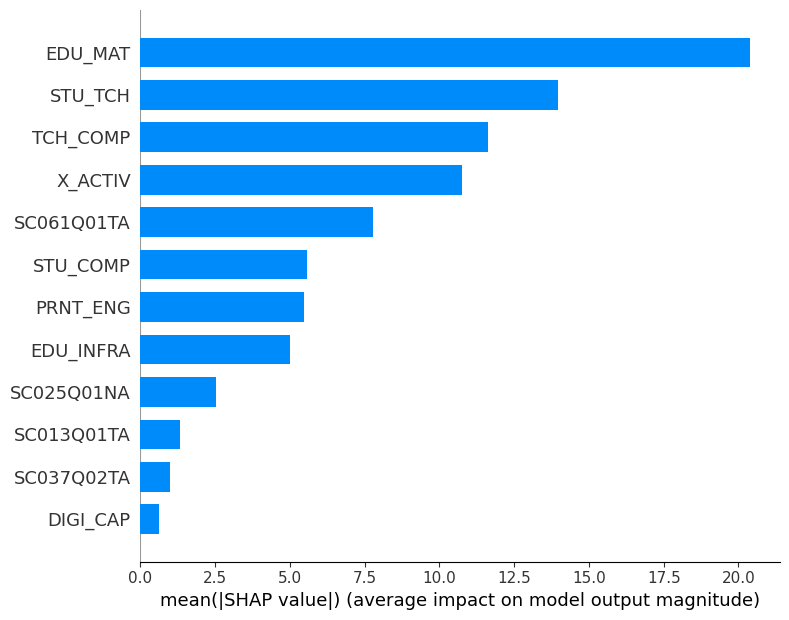


SHAP Summary (Beeswarm):


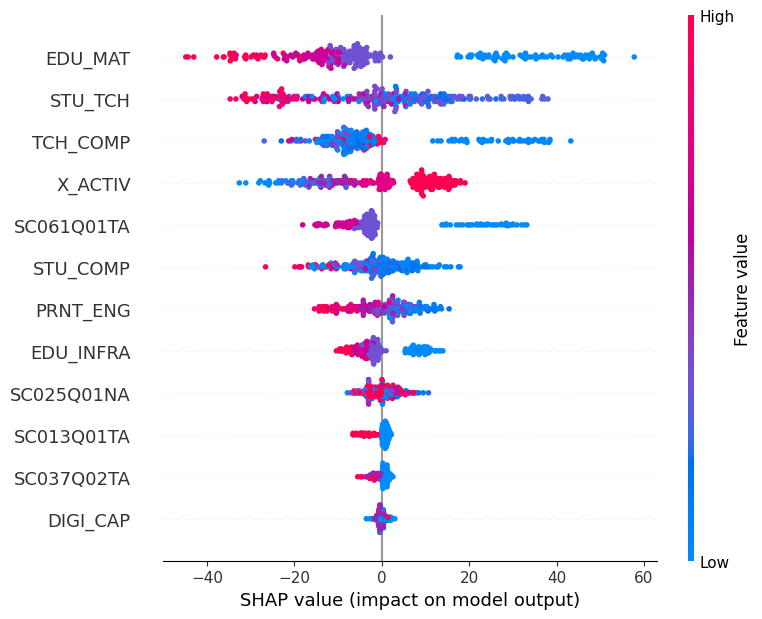

       feature  importance_mean  importance_std
4      EDU_MAT        11.041603        1.705053
7      STU_TCH         8.678906        1.852741
9     TCH_COMP         5.304109        1.055468
2   SC061Q01TA         4.819760        0.767568
10     X_ACTIV         4.190560        0.505894
11    PRNT_ENG         1.497117        0.354453
8     STU_COMP         1.145256        0.748964
5    EDU_INFRA         1.016719        0.592407
3   SC025Q01NA         0.340308        0.289444
0   SC013Q01TA         0.161867        0.204850
6     DIGI_CAP        -0.015453        0.079052
1   SC037Q02TA        -0.111436        0.159505


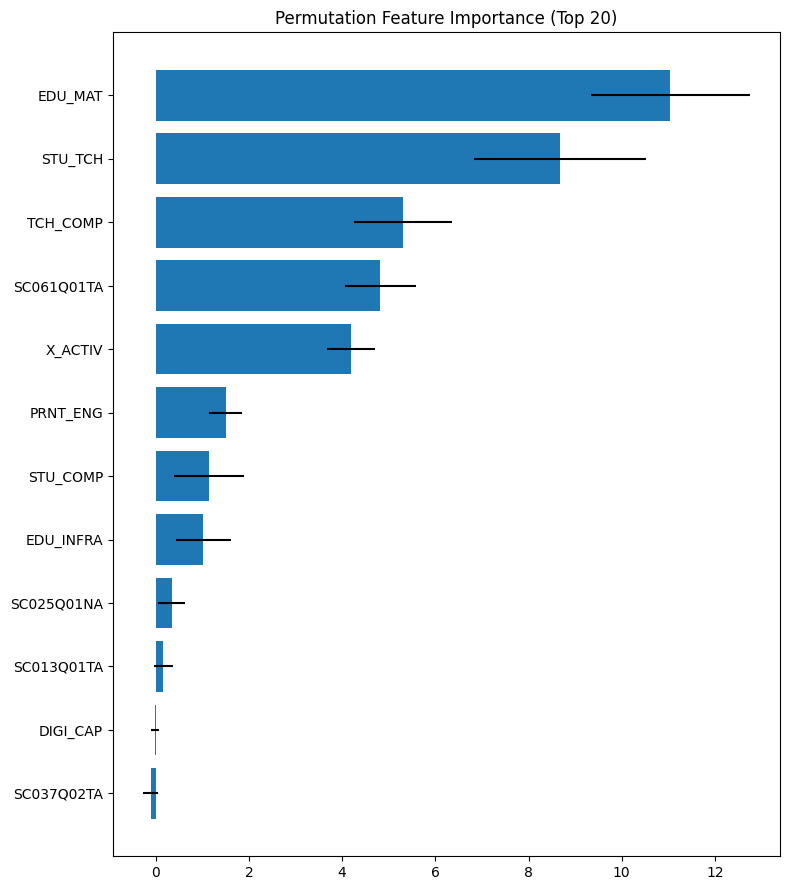

In [ ]:
#       Swap in df_merged_2022 if the 2022 frame was intended.
single_cycle_df = df_merged_2018
single_cycle_id_cols = ["CNT", "CNTSCHID", "CNTRYID", "ADMINMODE", "YEAR", "EXT_FUND"]

model_read, params_read, pfi_read, study_read, shap_read = train_xgb_and_shap_optuna_2022(
    single_cycle_df, target_col="READ_school_weighted", id_cols=single_cycle_id_cols)

In [46]:
shap_read.abs().mean().sort_values(ascending=False)

EDU_MAT       20.369728
STU_TCH       13.955400
TCH_COMP      11.615515
X_ACTIV       10.741821
SC061Q01TA     7.790251
STU_COMP       5.576768
PRNT_ENG       5.462480
EDU_INFRA      5.014900
SC025Q01NA     2.512040
SC013Q01TA     1.311414
SC037Q02TA     0.993983
DIGI_CAP       0.603975
dtype: float32


=== Training for SCIE_school_weighted (Optuna; stratified 2022 split) ===
Final X shape: (1286, 12)
Training observations: 1,028 | Untouched test observations: 258

Country × Year split audit:


split,test,train,total,train_pct,test_pct
stratum,,,,,
BRN__2018,11,44,55,80.000000,20.000000
IDN__2018,80,317,397,79.848866,20.151134
MYS__2018,38,153,191,80.104712,19.895288
PHL__2018,38,149,187,79.679144,20.320856
SGP__2018,33,133,166,80.120482,19.879518
THA__2018,58,232,290,80.000000,20.000000



Best params (Optuna): {'n_estimators': 850, 'learning_rate': 0.007577546162955336, 'max_depth': 9, 'subsample': 0.7373760764282102, 'colsample_bytree': 0.7231745698423145, 'reg_lambda': 16.263767710489155, 'min_child_weight': 10.807276933820672, 'gamma': 0.591627240413233, 'reg_alpha': 6.110702445689092}
Best CV RMSE: 49.823

Test MAE: 36.523 | RMSE: 47.089 | R^2: 0.616


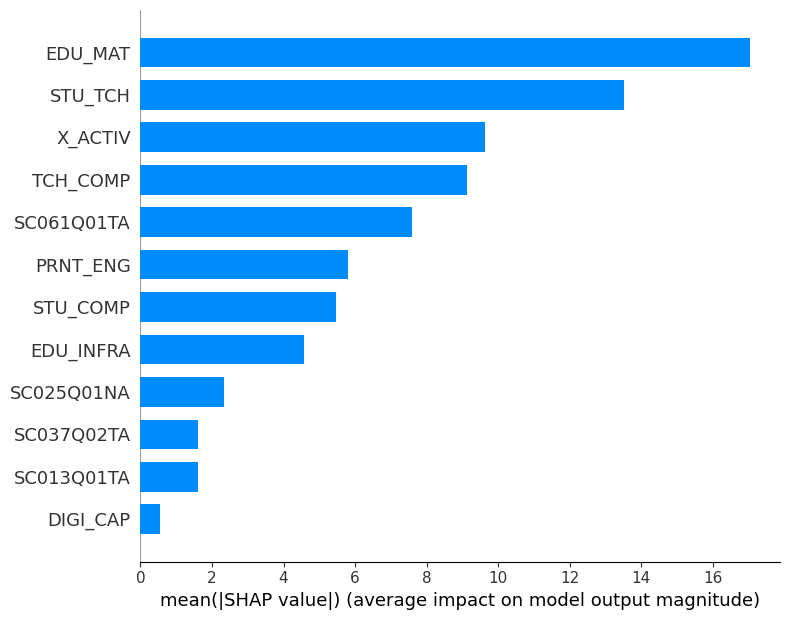


SHAP Summary (Beeswarm):


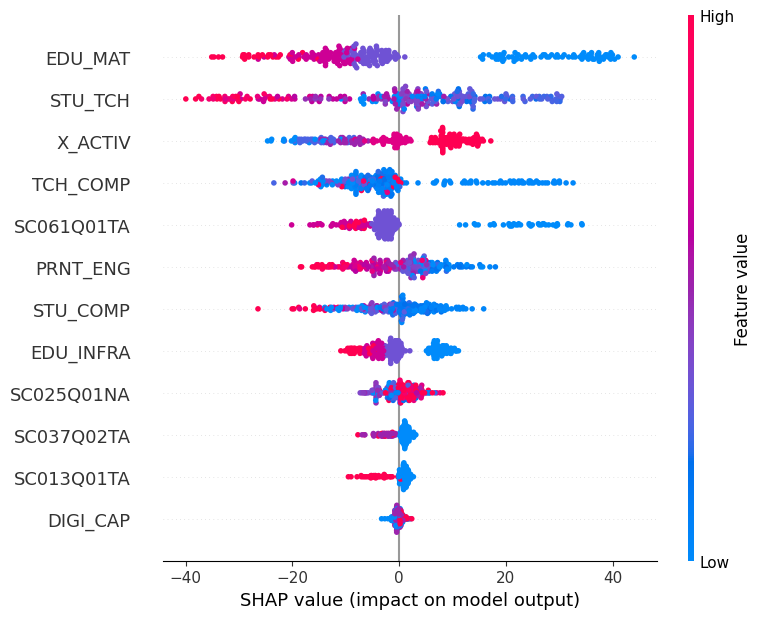

       feature  importance_mean  importance_std
4      EDU_MAT         8.794483        1.442756
7      STU_TCH         8.370042        1.623270
2   SC061Q01TA         5.455351        0.835769
9     TCH_COMP         4.645091        1.143163
10     X_ACTIV         3.714196        0.394456
11    PRNT_ENG         2.061877        0.395210
8     STU_COMP         1.846188        0.810767
5    EDU_INFRA         0.971126        0.522160
0   SC013Q01TA         0.353025        0.224796
3   SC025Q01NA         0.317491        0.284576
6     DIGI_CAP         0.085117        0.088216
1   SC037Q02TA        -0.109136        0.214038


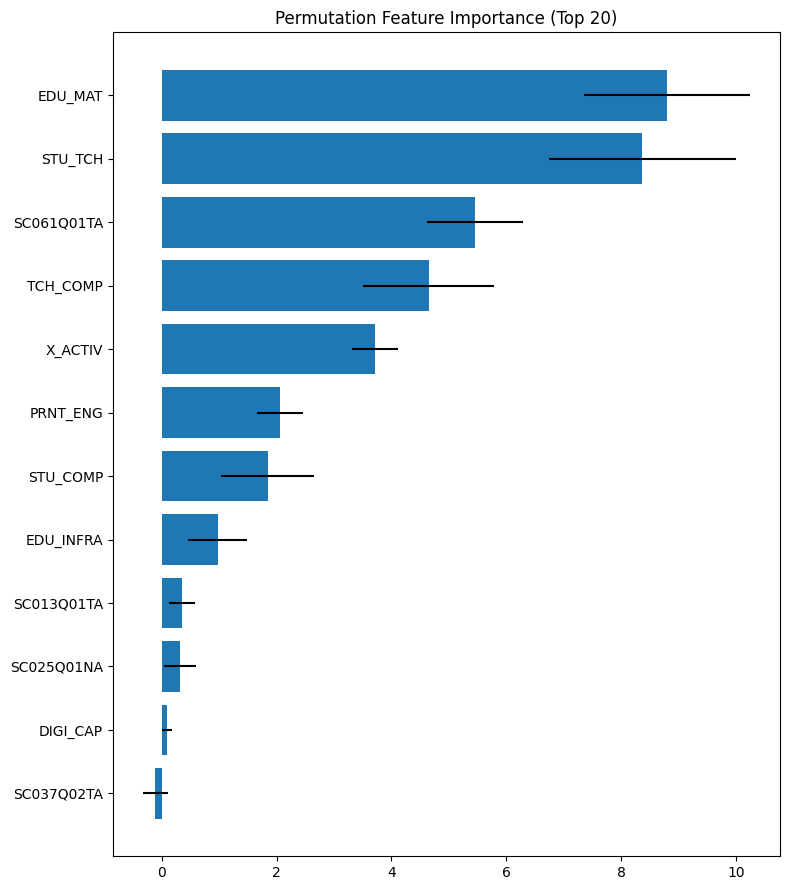

In [47]:
model_scie, params_scie, pfi_scie, study_scie, shap_scie = train_xgb_and_shap_optuna_2022(
    single_cycle_df, target_col="SCIE_school_weighted", id_cols=single_cycle_id_cols)

In [48]:
shap_scie.abs().mean().sort_values(ascending=False)

EDU_MAT       17.032372
STU_TCH       13.532887
X_ACTIV        9.643323
TCH_COMP       9.137918
SC061Q01TA     7.606537
PRNT_ENG       5.815753
STU_COMP       5.455385
EDU_INFRA      4.562541
SC025Q01NA     2.332797
SC037Q02TA     1.620137
SC013Q01TA     1.618910
DIGI_CAP       0.558402
dtype: float32


=== Training for MATH_school_weighted (Optuna; stratified 2022 split) ===
Final X shape: (1286, 12)
Training observations: 1,028 | Untouched test observations: 258

Country × Year split audit:


split,test,train,total,train_pct,test_pct
stratum,,,,,
BRN__2018,11,44,55,80.000000,20.000000
IDN__2018,80,317,397,79.848866,20.151134
MYS__2018,38,153,191,80.104712,19.895288
PHL__2018,38,149,187,79.679144,20.320856
SGP__2018,33,133,166,80.120482,19.879518
THA__2018,58,232,290,80.000000,20.000000



Best params (Optuna): {'n_estimators': 900, 'learning_rate': 0.006686606652938425, 'max_depth': 11, 'subsample': 0.7938797646876548, 'colsample_bytree': 0.7325649053258046, 'reg_lambda': 10.210224080873784, 'min_child_weight': 18.592741006647746, 'gamma': 4.4376110351475475, 'reg_alpha': 0.020733533448707597}
Best CV RMSE: 54.617

Test MAE: 42.309 | RMSE: 54.002 | R^2: 0.617


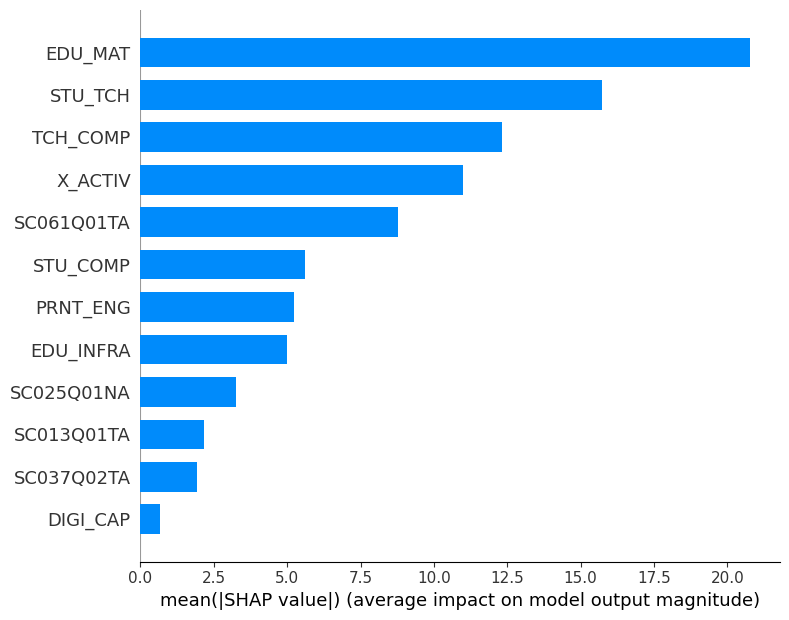


SHAP Summary (Beeswarm):


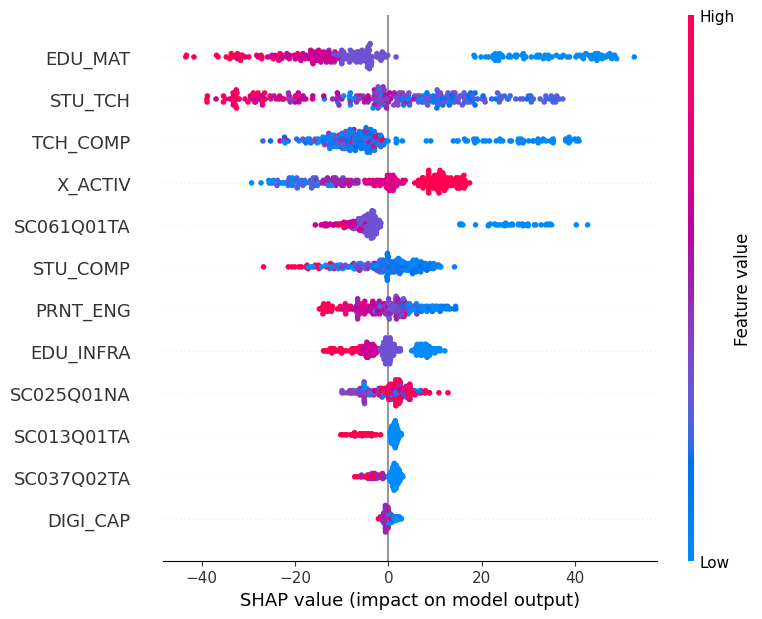

       feature  importance_mean  importance_std
4      EDU_MAT        11.410986        1.603301
7      STU_TCH        10.390948        1.970525
9     TCH_COMP         6.379854        1.152106
2   SC061Q01TA         5.019719        0.741870
10     X_ACTIV         4.047237        0.468600
8     STU_COMP         1.790220        0.696381
11    PRNT_ENG         1.509157        0.364135
5    EDU_INFRA         1.090758        0.501706
3   SC025Q01NA         0.614422        0.378612
0   SC013Q01TA         0.248685        0.268904
6     DIGI_CAP         0.092970        0.077063
1   SC037Q02TA        -0.172271        0.212014


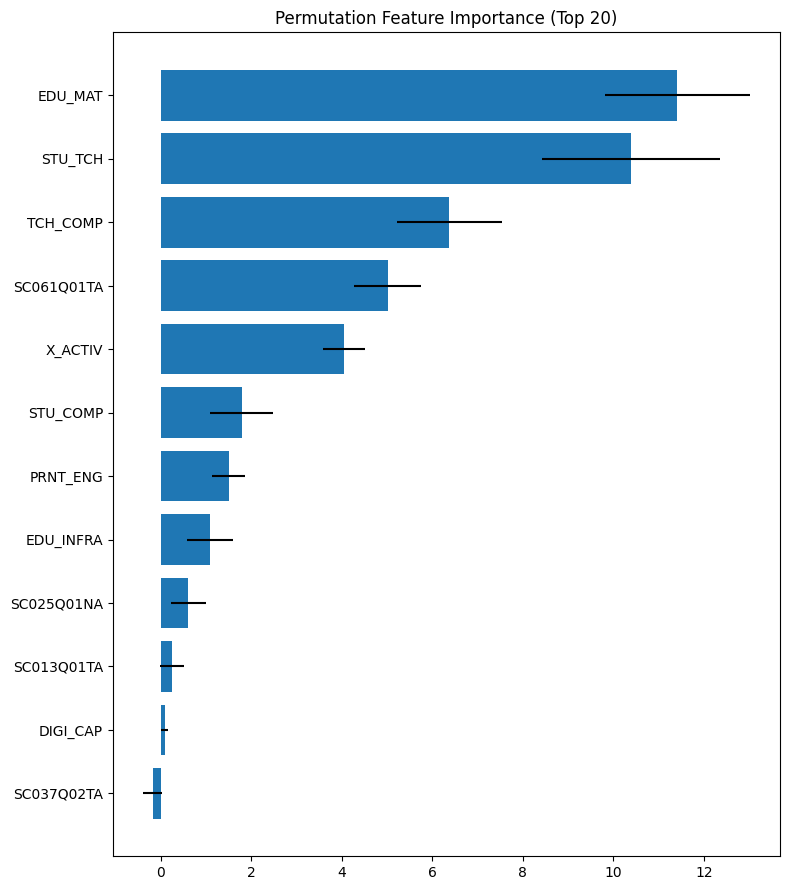

In [49]:
model_math, params_math, pfi_math, study_math, shap_math = train_xgb_and_shap_optuna_2022(
    single_cycle_df, target_col="MATH_school_weighted", id_cols=single_cycle_id_cols)

In [50]:
shap_math.abs().mean().sort_values(ascending=False)

EDU_MAT       20.757011
STU_TCH       15.743041
TCH_COMP      12.331845
X_ACTIV       10.981865
SC061Q01TA     8.784040
STU_COMP       5.600938
PRNT_ENG       5.222034
EDU_INFRA      4.978246
SC025Q01NA     3.241575
SC013Q01TA     2.157346
SC037Q02TA     1.910142
DIGI_CAP       0.657693
dtype: float32

In [64]:
stop  # run all stoppage

NameError: name 'stop' is not defined

### XGBOOST 2018 SEPARATED PVS READING


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import shap
import optuna
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from sklearn.impute import SimpleImputer


# 
def prepare_features_pv(df, target_col, id_cols):
    y = df[target_col].copy()
    X = df.drop(columns=id_cols + [target_col], errors="ignore").select_dtypes(include=[np.number]).copy()
    score_keywords = ["MATH", "READ", "SCIE", "PV", "ALL_DOMAIN", "WEIGHTED"]      # drop all PV / score columns
    X = X.drop(columns=[c for c in X.columns if any(k in c.upper() for k in score_keywords)], errors="ignore")
    mask = y.notna()
    X, y = X.loc[mask].copy(), y.loc[mask].copy()
    X = X.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
    X = X.drop(columns=[c for c in X.columns if X[c].isna().all()])
    print("Final X shape:", X.shape)
    return X, y


# 
def split_and_impute_pv(X, y, random_state):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_state)
    imputer = SimpleImputer(strategy="median")
    X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    X_test = pd.DataFrame(imputer.transform(X_test), columns=X_test.columns, index=X_test.index)
    return X_train, X_test, y_train, y_test


# 
def suggest_params_pv(trial, random_state):
    return {
        "objective": "reg:squarederror", "random_state": random_state, "n_jobs": 2,
        "n_estimators":     trial.suggest_int("n_estimators", 600, 1200, step=50),
        "learning_rate":    trial.suggest_float("learning_rate", 0.005, 0.03, log=True),
        "max_depth":        trial.suggest_int("max_depth", 4, 12),
        "subsample":        trial.suggest_float("subsample", 0.7, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0),
        "reg_lambda":       trial.suggest_float("reg_lambda", 1.0, 20.0, log=True),
        "min_child_weight": trial.suggest_float("min_child_weight", 1.0, 20.0, log=True),
        "gamma":            trial.suggest_float("gamma", 0.0, 5.0),
        "reg_alpha":        trial.suggest_float("reg_alpha", 0.0, 10.0),
    }


def _fit_with_early_stopping_pv(model, X_train, y_train, random_state, early_stopping_rounds):
    X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=random_state)
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False, early_stopping_rounds=early_stopping_rounds)
    return float(np.sqrt(mean_squared_error(y_val, model.predict(X_val))))


def tune_pv(X_train, y_train, n_trials, cv, random_state, timeout, use_early_stopping, early_stopping_rounds):
    def objective(trial):
        model = xgb.XGBRegressor(**suggest_params_pv(trial, random_state), base_score=float(y_train.mean()))
        if use_early_stopping:
            return _fit_with_early_stopping_pv(model, X_train, y_train, random_state, early_stopping_rounds)
        kf = KFold(n_splits=cv, shuffle=True, random_state=random_state)
        return float(-cross_val_score(model, X_train, y_train, scoring="neg_root_mean_squared_error",
                                      cv=kf, n_jobs=1).mean())

    study = optuna.create_study(direction="minimize")
    study.optimize(objective, n_trials=n_trials, timeout=timeout)
    print("\nBest params:", study.best_trial.params)
    print(f"Best CV RMSE: {study.best_value:.3f}")
    return study.best_trial.params, study


# 
def fit_final_pv(X_train, y_train, X_test, y_test, best_params, target_col, best_cv_rmse,
                 random_state, use_early_stopping, early_stopping_rounds):
    model = xgb.XGBRegressor(objective="reg:squarederror", random_state=random_state, n_jobs=2,
                             **best_params, base_score=float(y_train.mean()))
    if use_early_stopping:
        _fit_with_early_stopping_pv(model, X_train, y_train, random_state, early_stopping_rounds)
    else:
        model.fit(X_train, y_train)
    pred = model.predict(X_test)
    metrics = {"target_pv": target_col, "mae": mean_absolute_error(y_test, pred),
               "rmse": np.sqrt(mean_squared_error(y_test, pred)), "r2": r2_score(y_test, pred),
               "best_cv_rmse": best_cv_rmse}
    print(f"\nTest MAE: {metrics['mae']:.3f} | RMSE: {metrics['rmse']:.3f} | R^2: {metrics['r2']:.3f}")
    return model, metrics

In [ ]:
# 
def shap_pv(model, X_test, random_state, make_plots):
    X_shap = shap.sample(X_test, min(1000, len(X_test)), random_state=random_state)
    shap_values = model.get_booster().predict(xgb.DMatrix(X_shap, feature_names=list(X_shap.columns)),
                                              pred_contribs=True)[:, :-1]              # drop bias column
    if make_plots:
        print("\nTop Features - SHAP Bar:")
        shap.summary_plot(shap_values, X_shap, plot_type="bar", show=False); plt.tight_layout(); plt.show()
        print("\nSHAP Summary - Beeswarm:")
        shap.summary_plot(shap_values, X_shap, show=False, max_display=30); plt.tight_layout(); plt.show()
    return pd.DataFrame(shap_values, columns=X_shap.columns)


# 
def pfi_pv(model, X_test, y_test, target_col, random_state, make_plots, top_k=20):
    X_pfi = X_test.sample(min(2000, len(X_test)), random_state=random_state)
    pfi = permutation_importance(model, X_pfi, y_test.loc[X_pfi.index], n_repeats=10, random_state=random_state,
                                 n_jobs=1, scoring="neg_root_mean_squared_error")
    pfi_df = (pd.DataFrame({"feature": X_pfi.columns, "importance_mean": pfi.importances_mean,
                            "importance_std": pfi.importances_std}).sort_values("importance_mean", ascending=False))
    print(pfi_df.head(20))
    if make_plots:
        top = pfi_df.head(top_k).iloc[::-1]
        plt.figure(figsize=(8, 0.35 * top_k + 2))
        plt.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
        plt.title(f"Permutation Feature Importance - {target_col}"); plt.tight_layout(); plt.show()
    return pfi_df


# 
def train_xgb_and_shap_optuna_pv(df, target_col, id_cols, n_trials=40, cv=3, random_state=42, timeout=None,
                                 use_early_stopping=False, early_stopping_rounds=50, make_plots=True):
    print(f"\n=== Training for {target_col} ===")
    X, y = prepare_features_pv(df, target_col, id_cols)                                           # A
    X_train, X_test, y_train, y_test = split_and_impute_pv(X, y, random_state)                     # B
    best_params, study = tune_pv(X_train, y_train, n_trials, cv, random_state, timeout,            # C
                                 use_early_stopping, early_stopping_rounds)
    model, metrics = fit_final_pv(X_train, y_train, X_test, y_test, best_params, target_col,       # D
                                  study.best_value, random_state, use_early_stopping, early_stopping_rounds)
    shap_df = shap_pv(model, X_test, random_state, make_plots)                                     # E
    pfi_df = pfi_pv(model, X_test, y_test, target_col, random_state, make_plots)                   # F
    return model, best_params, pfi_df, study, shap_df, metrics

In [ ]:
# ---------- Run one model per READ PV ----------
pv_df = df_merged_2018_with_pv
pv_id_cols = ["CNT", "CNTSCHID", "CNTRYID", "ADMINMODE", "SC011Q01TA", "SC012Q01TA", "SC012Q02TA",
              "SC012Q03TA", "SC012Q04TA", "SC012Q05TA", "SC012Q06TA", "SC042Q01TA", "SC042Q02TA",
              "YEAR", "SC025Q01NA"]
read_pv_cols = [f"PV{i}READ_school" for i in range(1, 11)]
missing_read_pv_cols = [c for c in read_pv_cols if c not in pv_df.columns]
if missing_read_pv_cols:
    raise ValueError(f"Missing READ PV columns: {missing_read_pv_cols}")

read_pv_results = {}
for pv_col in read_pv_cols:
    model_pv, best_params_pv, pfi_df_pv, study_pv, shap_df_pv, metrics_pv = train_xgb_and_shap_optuna_pv(
        df=pv_df, target_col=pv_col, id_cols=pv_id_cols, n_trials=40, cv=3, random_state=42)
    read_pv_results[pv_col] = {"model": model_pv, "best_params": best_params_pv, "pfi_df": pfi_df_pv,
                               "study": study_pv, "shap_df": shap_df_pv, "metrics": metrics_pv}

In [ ]:
# ---------- Average across the 10 PVs: metrics, PFI, SHAP, plots ----------
read_pv_metrics_df = pd.DataFrame([r["metrics"] for r in read_pv_results.values()])
read_pv_average_metrics = read_pv_metrics_df.drop(columns="target_pv").mean().to_frame("average_across_READ_PVs")
display(read_pv_metrics_df)
display(read_pv_average_metrics)

read_pfi_all_df = pd.concat([r["pfi_df"].assign(target_pv=pv) for pv, r in read_pv_results.items()], ignore_index=True)
read_pfi_average_df = (read_pfi_all_df.groupby("feature", as_index=False)
                       .agg(importance_mean_avg=("importance_mean", "mean"), importance_std_avg=("importance_std", "mean"))
                       .sort_values("importance_mean_avg", ascending=False))
display(read_pfi_average_df.head(30))

read_shap_all_df = pd.concat([r["shap_df"].abs().mean().rename_axis("feature").reset_index(name="mean_abs_shap")
                              .assign(target_pv=pv) for pv, r in read_pv_results.items()], ignore_index=True)
read_shap_average_df = (read_shap_all_df.groupby("feature", as_index=False)
                        .agg(mean_abs_shap_avg=("mean_abs_shap", "mean"))
                        .sort_values("mean_abs_shap_avg", ascending=False))
display(read_shap_average_df.head(30))


def plot_average_importance(table, value_col, title, top_k=20):
    top = table.head(top_k).iloc[::-1]
    plt.figure(figsize=(8, 0.35 * top_k + 2))
    plt.barh(top["feature"], top[value_col]); plt.title(title); plt.tight_layout(); plt.show()


plot_average_importance(read_pfi_average_df, "importance_mean_avg", "Average Permutation Feature Importance across READ PVs")
plot_average_importance(read_shap_average_df, "mean_abs_shap_avg", "Average Mean Absolute SHAP across READ PVs")

### [RESULTS USED] STANDALONE TRAD OLS


In [53]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Step 1 — design matrix with optional country / year fixed-effect dummies
def build_ols_design(df, target_col, id_cols, country_col, year_col, add_country_fe, add_year_fe):
    cols_to_drop = id_cols + [target_col]                 # keep country/year if they become FE dummies
    if add_country_fe and country_col in cols_to_drop:
        cols_to_drop.remove(country_col)
    if add_year_fe and year_col in cols_to_drop:
        cols_to_drop.remove(year_col)
    X = df.drop(columns=cols_to_drop, errors="ignore").copy()

    fe_cols = []
    for use_fe, col in [(add_country_fe, country_col), (add_year_fe, year_col)]:
        if not use_fe:
            continue
        if col not in df.columns:
            raise ValueError(f"`{col}` not found in df.")
        dummies = pd.get_dummies(df[col], prefix=col, drop_first=True, dtype=float)
        X = pd.concat([X.drop(columns=[col], errors="ignore"), dummies], axis=1)
        fe_cols += dummies.columns.tolist()
    return X.select_dtypes(include=[np.number]), fe_cols


# Step 2 — drop score leakage, then listwise deletion
def filter_ols_rows(X, y, target_col, cluster_groups=None):
    score_keywords = ["MATH", "READ", "SCIE", "PV", "ALL_DOMAIN"]
    X = X.drop(columns=[c for c in X.columns if any(k in c.upper() for k in score_keywords) and c != target_col],
               errors="ignore")
    X = X.replace([np.inf, -np.inf], np.nan)
    mask = y.notna() & X.notna().all(axis=1)
    if cluster_groups is not None:
        cluster_groups = cluster_groups.loc[mask]
    if X.shape[1] == 0:
        raise ValueError("No usable predictors remain after exclusions.")
    return X.loc[mask], y.loc[mask], cluster_groups


# Step 3 — optional standardization of non-FE predictors
def standardize_non_fe(X, fe_cols):
    non_fe_cols = [c for c in X.columns if c not in fe_cols]
    scaler = StandardScaler()
    X = X.copy()
    if non_fe_cols:
        X[non_fe_cols] = scaler.fit_transform(X[non_fe_cols])
    return X, scaler


# Step 4 — VIF and optional iterative pruning (FE dummies are protected)
def compute_vif(X_df):
    Xv = sm.add_constant(X_df, has_constant="add")
    vifs = []
    for i, col in enumerate(Xv.columns):
        if col == "const":
            continue
        try:
            vifs.append((col, variance_inflation_factor(Xv.values, i)))
        except Exception:
            vifs.append((col, np.nan))
    return pd.DataFrame(vifs, columns=["feature", "VIF"]).sort_values("VIF", ascending=False)


def prune_by_vif(X, vif_max, protected_cols):
    while X.shape[1] > 2:
        vif_now = compute_vif(X)
        candidates = vif_now[~vif_now["feature"].isin(protected_cols)]
        if candidates.empty:
            break
        worst = candidates.iloc[0]
        if pd.isna(worst["VIF"]) or worst["VIF"] <= vif_max:
            break
        print(f"Dropping '{worst['feature']}' due to high VIF={worst['VIF']:.2f}")
        X = X.drop(columns=[worst["feature"]])
    return X


# Step 5 — fit with robust or clustered SEs
def fit_ols(X, y, robust_se, cluster_groups):
    X_sm = sm.add_constant(X, has_constant="add")
    if robust_se == "cluster":
        if cluster_groups is None:
            raise ValueError("For clustered SE, provide `cluster_col`.")
        return sm.OLS(y, X_sm).fit(cov_type="cluster", cov_kwds={"groups": cluster_groups}), X_sm
    return sm.OLS(y, X_sm).fit(cov_type=robust_se), X_sm


# Step 6 — coefficient table (sorted by p-value, constant last)
def make_coef_table(res):
    ci = res.conf_int()
    coef = pd.DataFrame({"coef": res.params, "std_err": res.bse, "t": res.tvalues, "p_value": res.pvalues,
                         "ci_low": ci[0], "ci_high": ci[1]}).sort_values("p_value")
    if "const" in coef.index:
        coef = pd.concat([coef.drop(index=["const"]), coef.loc[["const"]]])
    return coef


def run_pooled_ols_fe(df, target_col, id_cols, country_col="CNT_x", year_col="YEAR", add_country_fe=True,
                      add_year_fe=True, standardize=False, robust_se="HC3", cluster_col=None, vif=True, vif_max=None):
    print(f"\n=== Pooled OLS for {target_col} ===")
    y = df[target_col].copy()
    cluster_groups = df[cluster_col].copy() if cluster_col is not None and cluster_col in df.columns else None

    X, fe_cols = build_ols_design(df, target_col, id_cols, country_col, year_col, add_country_fe, add_year_fe)  # 1
    X, y, cluster_groups = filter_ols_rows(X, y, target_col, cluster_groups)                                   # 2
    print("Final X shape:", X.shape, "| Country FE:", add_country_fe, "| Year FE:", add_year_fe)

    scaler = None
    if standardize:                                                                                            # 3
        X, scaler = standardize_non_fe(X, fe_cols)

    vif_df = None
    if vif:                                                                                                    # 4
        vif_df = compute_vif(X)
        print("\nTop VIFs:\n", vif_df.head(10))
        if vif_max is not None:
            X = prune_by_vif(X, vif_max, set(fe_cols))
            vif_df = compute_vif(X)

    res, X_sm = fit_ols(X, y, robust_se, cluster_groups)                                                        # 5

    pred = res.predict(X_sm)                                                                                   # 6
    metrics = {"mae": mean_absolute_error(y, pred), "rmse": np.sqrt(mean_squared_error(y, pred)), "r2": r2_score(y, pred)}
    print(f"\nIn-sample MAE: {metrics['mae']:.3f} | RMSE: {metrics['rmse']:.3f} | R²: {metrics['r2']:.3f}")
    print("\nOLS summary:\n", res.summary())

    return {"results": res, "metrics": metrics, "coef_table": make_coef_table(res), "vif_table": vif_df,
            "used_features": X.columns.tolist(), "fixed_effect_cols": fe_cols, "scaler": scaler}

#### POOLED OLS

In [54]:
ols_read_pooled = run_pooled_ols_fe(
    df=df_merged_combined,
    target_col="READ_school_weighted",
    id_cols=[
        "CNT_x", "CNT_y", "CNTSCHID", "CNTRYID", "ADMINMODE"
    ],
    country_col="CNT_x",
    year_col="YEAR",
    add_country_fe=False,
    add_year_fe=False,
    standardize=False,
    robust_se="HC3",
    cluster_col="CNT_x",
    vif=True,
    vif_max=None,
)


=== Pooled OLS for READ_school_weighted ===
Final X shape: (2941, 14) | Country FE: False | Year FE: False

Top VIFs:
        feature       VIF
6      EDU_MAT  1.864310
7    EDU_INFRA  1.825748
0   SC013Q01TA  1.650051
5     EXT_FUND  1.614034
12     X_ACTIV  1.292679
4         YEAR  1.238910
3   SC025Q01NA  1.188086
8     DIGI_CAP  1.165701
2   SC061Q01TA  1.146406
13    PRNT_ENG  1.136693

In-sample MAE: 48.699 | RMSE: 61.542 | R²: 0.414

OLS summary:
                              OLS Regression Results                             
Dep. Variable:     READ_school_weighted   R-squared:                       0.414
Model:                              OLS   Adj. R-squared:                  0.411
Method:                   Least Squares   F-statistic:                     129.8
Date:                  Mon, 28 Sep 2026   Prob (F-statistic):          4.22e-294
Time:                          22:43:35   Log-Likelihood:                -16289.
No. Observations:                  2941   AIC:        

In [55]:
ols_math_pooled = run_pooled_ols_fe(
    df=df_merged_combined,
    target_col="MATH_school_weighted",
    id_cols=[
        "CNT_x", "CNT_y", "CNTSCHID", "CNTRYID", "ADMINMODE"
    ],
    country_col="CNT_x",
    year_col="YEAR",
    add_country_fe=False,
    add_year_fe=False,
    standardize=False,
    robust_se="HC3",
    cluster_col="CNT_x",
    vif=True,
    vif_max=None,
)


=== Pooled OLS for MATH_school_weighted ===
Final X shape: (2941, 14) | Country FE: False | Year FE: False

Top VIFs:
        feature       VIF
6      EDU_MAT  1.864310
7    EDU_INFRA  1.825748
0   SC013Q01TA  1.650051
5     EXT_FUND  1.614034
12     X_ACTIV  1.292679
4         YEAR  1.238910
3   SC025Q01NA  1.188086
8     DIGI_CAP  1.165701
2   SC061Q01TA  1.146406
13    PRNT_ENG  1.136693

In-sample MAE: 49.442 | RMSE: 62.890 | R²: 0.445

OLS summary:
                              OLS Regression Results                             
Dep. Variable:     MATH_school_weighted   R-squared:                       0.445
Model:                              OLS   Adj. R-squared:                  0.442
Method:                   Least Squares   F-statistic:                     147.6
Date:                  Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                          22:43:35   Log-Likelihood:                -16353.
No. Observations:                  2941   AIC:        

In [56]:
ols_scie_pooled = run_pooled_ols_fe(
    df=df_merged_combined,
    target_col="SCIE_school_weighted",
    id_cols=[
        "CNT_x", "CNT_y", "CNTSCHID", "CNTRYID", "ADMINMODE"
    ],
    country_col="CNT_x",
    year_col="YEAR",
    add_country_fe=False,
    add_year_fe=False,
    standardize=False,
    robust_se="HC3",
    cluster_col="CNT_x",
    vif=True,
    vif_max=None,
)


=== Pooled OLS for SCIE_school_weighted ===
Final X shape: (2941, 14) | Country FE: False | Year FE: False

Top VIFs:
        feature       VIF
6      EDU_MAT  1.864310
7    EDU_INFRA  1.825748
0   SC013Q01TA  1.650051
5     EXT_FUND  1.614034
12     X_ACTIV  1.292679
4         YEAR  1.238910
3   SC025Q01NA  1.188086
8     DIGI_CAP  1.165701
2   SC061Q01TA  1.146406
13    PRNT_ENG  1.136693

In-sample MAE: 44.608 | RMSE: 56.609 | R²: 0.446

OLS summary:
                              OLS Regression Results                             
Dep. Variable:     SCIE_school_weighted   R-squared:                       0.446
Model:                              OLS   Adj. R-squared:                  0.444
Method:                   Least Squares   F-statistic:                     145.1
Date:                  Mon, 28 Sep 2026   Prob (F-statistic):          7.07e-322
Time:                          22:43:35   Log-Likelihood:                -16043.
No. Observations:                  2941   AIC:        

#### FIXED EFFECTS

In [57]:
ols_read_fe = run_pooled_ols_fe(
    df=df_merged_combined,
    target_col="READ_school_weighted",
    id_cols=[
        "CNT_x", "CNT_y", "CNTSCHID", "CNTRYID", "ADMINMODE"
    ],
    country_col="CNT_x",
    year_col="YEAR",
    add_country_fe=True,
    add_year_fe=True,
    standardize=False,
    robust_se="HC3",
    cluster_col="CNT_x",
    vif=True,
    vif_max=None,
)


=== Pooled OLS for READ_school_weighted ===
Final X shape: (2941, 21) | Country FE: True | Year FE: True

Top VIFs:
        feature       VIF
13   CNT_x_IDN  7.138895
18   CNT_x_THA  5.608912
16   CNT_x_PHL  4.985201
15   CNT_x_MYS  4.223767
17   CNT_x_SGP  3.907183
14   CNT_x_KHM  3.251544
19   CNT_x_VNM  2.750817
5      EDU_MAT  1.988453
6    EDU_INFRA  1.861679
0   SC013Q01TA  1.841526

In-sample MAE: 37.407 | RMSE: 48.108 | R²: 0.642

OLS summary:
                              OLS Regression Results                             
Dep. Variable:     READ_school_weighted   R-squared:                       0.642
Model:                              OLS   Adj. R-squared:                  0.639
Method:                   Least Squares   F-statistic:                     272.8
Date:                  Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                          22:43:35   Log-Likelihood:                -15565.
No. Observations:                  2941   AIC:          

In [58]:
ols_math_fe = run_pooled_ols_fe(
    df=df_merged_combined,
    target_col="MATH_school_weighted",
    id_cols=[
        "CNT_x", "CNT_y", "CNTSCHID", "CNTRYID", "ADMINMODE"
    ],
    country_col="CNT_x",
    year_col="YEAR",
    add_country_fe=True,
    add_year_fe=True,
    standardize=False,
    robust_se="HC3",
    cluster_col="CNT_x",
    vif=True,
    vif_max=None,
)


=== Pooled OLS for MATH_school_weighted ===
Final X shape: (2941, 21) | Country FE: True | Year FE: True

Top VIFs:
        feature       VIF
13   CNT_x_IDN  7.138895
18   CNT_x_THA  5.608912
16   CNT_x_PHL  4.985201
15   CNT_x_MYS  4.223767
17   CNT_x_SGP  3.907183
14   CNT_x_KHM  3.251544
19   CNT_x_VNM  2.750817
5      EDU_MAT  1.988453
6    EDU_INFRA  1.861679
0   SC013Q01TA  1.841526

In-sample MAE: 36.714 | RMSE: 48.272 | R²: 0.673

OLS summary:
                              OLS Regression Results                             
Dep. Variable:     MATH_school_weighted   R-squared:                       0.673
Model:                              OLS   Adj. R-squared:                  0.671
Method:                   Least Squares   F-statistic:                     327.6
Date:                  Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                          22:43:35   Log-Likelihood:                -15575.
No. Observations:                  2941   AIC:          

In [59]:
ols_scie_fe = run_pooled_ols_fe(
    df=df_merged_combined,
    target_col="SCIE_school_weighted",
    id_cols=[
        "CNT_x", "CNT_y", "CNTSCHID", "CNTRYID", "ADMINMODE"
    ],
    country_col="CNT_x",
    year_col="YEAR",
    add_country_fe=True,
    add_year_fe=True,
    standardize=False,
    robust_se="HC3",
    cluster_col="CNT_x",
    vif=True,
    vif_max=None,
)


=== Pooled OLS for SCIE_school_weighted ===
Final X shape: (2941, 21) | Country FE: True | Year FE: True

Top VIFs:
        feature       VIF
13   CNT_x_IDN  7.138895
18   CNT_x_THA  5.608912
16   CNT_x_PHL  4.985201
15   CNT_x_MYS  4.223767
17   CNT_x_SGP  3.907183
14   CNT_x_KHM  3.251544
19   CNT_x_VNM  2.750817
5      EDU_MAT  1.988453
6    EDU_INFRA  1.861679
0   SC013Q01TA  1.841526

In-sample MAE: 34.453 | RMSE: 44.882 | R²: 0.652

OLS summary:
                              OLS Regression Results                             
Dep. Variable:     SCIE_school_weighted   R-squared:                       0.652
Model:                              OLS   Adj. R-squared:                  0.649
Method:                   Least Squares   F-statistic:                     296.3
Date:                  Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                          22:43:35   Log-Likelihood:                -15361.
No. Observations:                  2941   AIC:          